### Importando bibliotecas

In [42]:
# Carregamento de dados
from joblib import load, dump
import os

# Processamento de dados
import numpy as np
import pandas as pd

# Graficos
import seaborn as sns
import matplotlib.pyplot as plt

# Funções de clustering
from src.clustering import Clustering

In [29]:
#Modelos de aprendizado de máquina
from sklearn.datasets import load_iris
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import KFold, cross_val_score, StratifiedKFold

## Cross Validation and Grid Search

In [30]:
#Validação cruzada K-Fold
data = load_iris()
X, y = data.data, data.target

model = LogisticRegression(max_iter=200)
kfold = KFold(n_splits=5, shuffle=True, random_state=42)

scores = cross_val_score(model, X, y, cv=kfold, scoring="accuracy")

print(f"Scores per fold: {scores}")
print(f"Mean Accuracy: {np.mean(scores):.4f}")
print(f"Standard Deviation: {np.std(scores):.4f}")

Scores per fold: [1.         1.         0.93333333 0.96666667 0.96666667]
Mean Accuracy: 0.9733
Standard Deviation: 0.0249


In [31]:
#Validação cruzada estratificada
kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scores = cross_val_score(model, X, y, cv=kfold, scoring="accuracy")

print(f"Scores per fold: {scores}")
print(f"Mean Accuracy: {np.mean(scores):.4f}")
print(f"Standard Deviation: {np.std(scores):.4f}")


Scores per fold: [1.         0.96666667 0.93333333 1.         0.93333333]
Mean Accuracy: 0.9667
Standard Deviation: 0.0298


In [32]:
#Identificando arquivos de treino e teste
os.listdir("../tabelas/tabelas_finais")

['X_train.csv',
 'y_valid.csv',
 'y_train.csv',
 'y_test.csv',
 'X_test.csv',
 'X_valid.csv']

In [33]:
#Concatenando tabelas de treino
df_train = pd.concat(
    [
        pd.read_csv("../tabelas/tabelas_finais/X_train.csv"),
        pd.read_csv("../tabelas/tabelas_finais/y_train.csv"),
    ],
    axis=1,
)

In [34]:
#Concatenando tabelas de validação
df_valid = pd.concat(
    [
        pd.read_csv("../tabelas/tabelas_finais/X_valid.csv"),
        pd.read_csv("../tabelas/tabelas_finais/y_valid.csv"),
    ],
    axis=1,
)

In [35]:
#Concatenando tabelas de teste
df_test = pd.concat(
    [
        pd.read_csv("../tabelas/tabelas_finais/X_test.csv"),
        pd.read_csv("../tabelas/tabelas_finais/y_test.csv"),
    ],
    axis=1,
)

### Validação cruzada e busca de hiperparâmetros

# Treino

K-means

In [36]:
#Definindo um objeto com os dados de treino
nome_modelo = "kmeans"
bivariadas =  [
    ['n_tetraciclina', 'n_polimixinas'],
    ['n_tetraciclina', 'n_virulencia_clinica'],
    ['n_tetraciclina', 'n_ilha_AbaR'],
    ['n_tetraciclina', 'n_resistencia_metais'],
    ['n_tetraciclina', 'n_degradacao_aromaticos'],
    ['n_polimixinas', 'n_virulencia_clinica'],
    ['n_polimixinas', 'n_ilha_AbaR'],
    ['n_polimixinas', 'n_resistencia_metais'],
    ['n_polimixinas', 'n_degradacao_aromaticos'],
    ['n_virulencia_clinica', 'n_ilha_AbaR']
]
cluster = Clustering(
    c1=bivariadas[0][0], c2=bivariadas[0][1], df=df_train, modelo=nome_modelo
)
cluster.cross_validation(print_metricas=False)[0][:5]

/home/isabel.ribeiro/.conda/envs/ml_clusterizacao/lib/python3.10/site-packages/sklearn/base.py:1474: ConvergenceWarning: Number of distinct clusters (3) found smaller than n_clusters (4). Possibly due to duplicate points in X.
  return fit_method(estimator, *args, **kwargs)
/home/isabel.ribeiro/.conda/envs/ml_clusterizacao/lib/python3.10/site-packages/sklearn/base.py:1474: ConvergenceWarning: Number of distinct clusters (3) found smaller than n_clusters (4). Possibly due to duplicate points in X.
  return fit_method(estimator, *args, **kwargs)
/home/isabel.ribeiro/.conda/envs/ml_clusterizacao/lib/python3.10/site-packages/sklearn/base.py:1474: ConvergenceWarning: Number of distinct clusters (3) found smaller than n_clusters (4). Possibly due to duplicate points in X.
  return fit_method(estimator, *args, **kwargs)
/home/isabel.ribeiro/.conda/envs/ml_clusterizacao/lib/python3.10/site-packages/sklearn/base.py:1474: ConvergenceWarning: Number of distinct clusters (3) found smaller than n_c

array([0, 0, 0, 0, 1], dtype=int32)

In [37]:
#Obtendo as métricas de avaliação para todas as combinações
data = {}
for i in df_train.columns[:-1]:
    for j in df_train.columns[:-1]:
        if i != j:
            cluster = Clustering(c1=i, c2=j, df=df_train, modelo=nome_modelo)
            _, metricas = cluster.cross_validation(print_metricas=False)
            data[i + "_" + j] = metricas
df_metricas = pd.DataFrame(data).T.rename(
    columns={
        0: "Silhouette",
        1: "Calinski Harabasz",
        2: "Davies Bouldin",
        3: "Adjusted Rand",
        4: "Adjusted Mutual Info",
    }
)
df_metricas.head()

/home/isabel.ribeiro/.conda/envs/ml_clusterizacao/lib/python3.10/site-packages/sklearn/base.py:1474: ConvergenceWarning: Number of distinct clusters (4) found smaller than n_clusters (6). Possibly due to duplicate points in X.
  return fit_method(estimator, *args, **kwargs)
/home/isabel.ribeiro/.conda/envs/ml_clusterizacao/lib/python3.10/site-packages/sklearn/base.py:1474: ConvergenceWarning: Number of distinct clusters (4) found smaller than n_clusters (6). Possibly due to duplicate points in X.
  return fit_method(estimator, *args, **kwargs)
/home/isabel.ribeiro/.conda/envs/ml_clusterizacao/lib/python3.10/site-packages/sklearn/base.py:1474: ConvergenceWarning: Number of distinct clusters (4) found smaller than n_clusters (6). Possibly due to duplicate points in X.
  return fit_method(estimator, *args, **kwargs)
/home/isabel.ribeiro/.conda/envs/ml_clusterizacao/lib/python3.10/site-packages/sklearn/base.py:1474: ConvergenceWarning: Number of distinct clusters (4) found smaller than n_c

,Silhouette,Calinski Harabasz,Davies Bouldin,Adjusted Rand,Adjusted Mutual Info
n_OXA_n_MBL,1.000,3.594766e+31,0.000,0.113,0.114
n_OXA_n_ISAba1,0.826,1.977523e+03,0.538,0.051,0.064
n_OXA_n_ESBL,0.725,1.214094e+03,0.627,0.152,0.226
n_OXA_n_aminoglicosideos,0.676,1.315513e+03,0.703,0.160,0.206
n_OXA_n_sulfa_trimetoprim,0.750,1.178454e+03,0.611,0.162,0.224


In [38]:
#Selecionando as melhores combinações de variáveis
display(df_metricas["Silhouette"].nlargest(1))
display(df_metricas["Calinski Harabasz"].nsmallest(1))
display(df_metricas["Davies Bouldin"].nlargest(1))
display(df_metricas["Adjusted Rand"].nlargest(1))
display(df_metricas["Adjusted Mutual Info"].nlargest(1))

n_OXA_n_MBL    1.0
Name: Silhouette, dtype: float64

n_OXA_n_sulfa_trimetoprim    1178.454
Name: Calinski Harabasz, dtype: float64

n_ISAba1_n_aminoglicosideos    0.71
Name: Davies Bouldin, dtype: float64

n_tetraciclina_n_polimixinas    0.723
Name: Adjusted Rand, dtype: float64

n_tetraciclina_n_ilha_AbaR    0.628
Name: Adjusted Mutual Info, dtype: float64

In [39]:
for indice, par in enumerate(bivariadas):
    print(indice, par)

0 ['n_tetraciclina', 'n_polimixinas']
1 ['n_tetraciclina', 'n_virulencia_clinica']
2 ['n_tetraciclina', 'n_ilha_AbaR']
3 ['n_tetraciclina', 'n_resistencia_metais']
4 ['n_tetraciclina', 'n_degradacao_aromaticos']
5 ['n_polimixinas', 'n_virulencia_clinica']
6 ['n_polimixinas', 'n_ilha_AbaR']
7 ['n_polimixinas', 'n_resistencia_metais']
8 ['n_polimixinas', 'n_degradacao_aromaticos']
9 ['n_virulencia_clinica', 'n_ilha_AbaR']


/home/isabel.ribeiro/.conda/envs/ml_clusterizacao/lib/python3.10/site-packages/sklearn/base.py:1474: ConvergenceWarning: Number of distinct clusters (3) found smaller than n_clusters (4). Possibly due to duplicate points in X.
  return fit_method(estimator, *args, **kwargs)
/home/isabel.ribeiro/.conda/envs/ml_clusterizacao/lib/python3.10/site-packages/sklearn/base.py:1474: ConvergenceWarning: Number of distinct clusters (3) found smaller than n_clusters (4). Possibly due to duplicate points in X.
  return fit_method(estimator, *args, **kwargs)
/home/isabel.ribeiro/.conda/envs/ml_clusterizacao/lib/python3.10/site-packages/sklearn/base.py:1474: ConvergenceWarning: Number of distinct clusters (3) found smaller than n_clusters (4). Possibly due to duplicate points in X.
  return fit_method(estimator, *args, **kwargs)
/home/isabel.ribeiro/.conda/envs/ml_clusterizacao/lib/python3.10/site-packages/sklearn/base.py:1474: ConvergenceWarning: Number of distinct clusters (3) found smaller than n_c

=== MELHOR CONFIGURAÇÃO ENCONTRADA VIA cross_val_score ===
Parâmetros: {'n_clusters': 4, 'init': 'k-means++', 'n_init': 'auto'}
Silhouette Score Médio (CV): 1.0000

Silhouette Score -> 1.0
Calinski Harabasz Score -> 1.869472497498417e+31
Davies Bouldin Score -> 0.0
Adjusted Rand Score -> 0.723
Adjusted Mutual Info Score -> 0.597


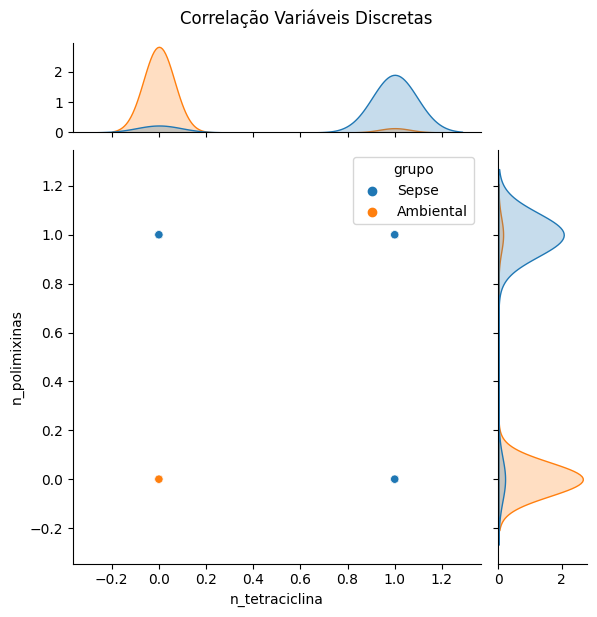

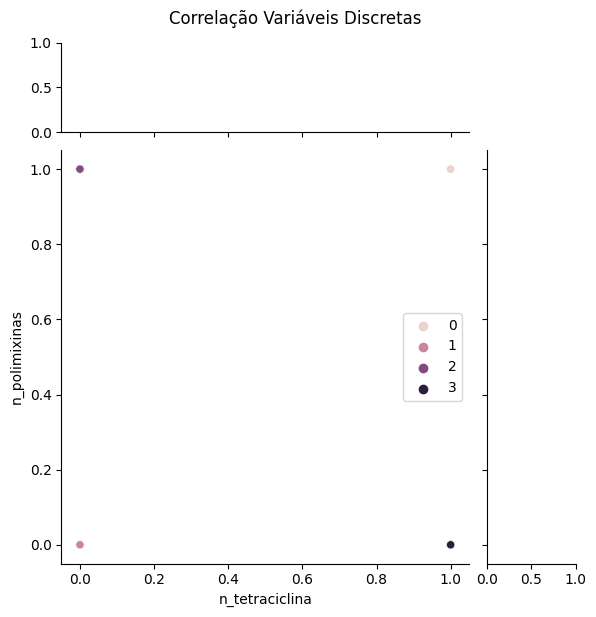

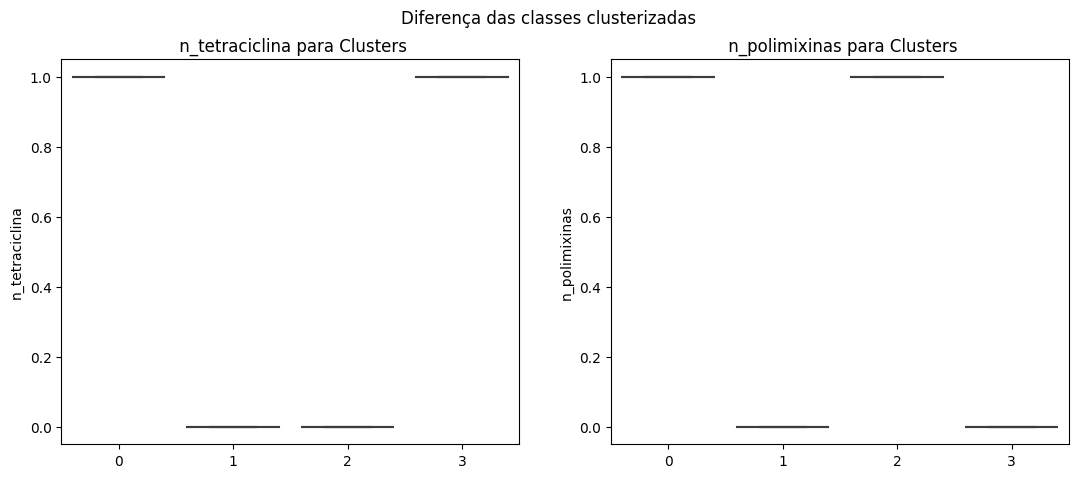

In [43]:
#Avaliando entre n_tetraciclina e n_polimixinas
i = bivariadas[0][0]
j = bivariadas[0][1]

cluster = Clustering(c1=i, c2=j, df=df_train, modelo=nome_modelo)
cluster.cross_validation()

In [ ]:
for indice, par in enumerate(bivariadas):
    print(indice, par)

0 ['n_tetraciclina', 'n_polimixinas']
1 ['n_tetraciclina', 'n_virulencia_clinica']
2 ['n_tetraciclina', 'n_ilha_AbaR']
3 ['n_tetraciclina', 'n_resistencia_metais']
4 ['n_tetraciclina', 'n_degradacao_aromaticos']
5 ['n_polimixinas', 'n_virulencia_clinica']
6 ['n_polimixinas', 'n_ilha_AbaR']
7 ['n_polimixinas', 'n_resistencia_metais']
8 ['n_polimixinas', 'n_degradacao_aromaticos']
9 ['n_virulencia_clinica', 'n_ilha_AbaR']


In [ ]:
for indice, par in enumerate(bivariadas):
    print(indice, par)

0 ['n_tetraciclina', 'n_polimixinas']
1 ['n_tetraciclina', 'n_virulencia_clinica']
2 ['n_tetraciclina', 'n_ilha_AbaR']
3 ['n_tetraciclina', 'n_resistencia_metais']
4 ['n_tetraciclina', 'n_degradacao_aromaticos']
5 ['n_polimixinas', 'n_virulencia_clinica']
6 ['n_polimixinas', 'n_ilha_AbaR']
7 ['n_polimixinas', 'n_resistencia_metais']
8 ['n_polimixinas', 'n_degradacao_aromaticos']
9 ['n_virulencia_clinica', 'n_ilha_AbaR']


In [27]:
#Analisando os clusters para variável n_tetraciclina e n_ilha_AbaR
i = bivariadas[2][0]
j = bivariadas[2][1]
cluster = Clustering(c1=i, c2=j, df=df_train, modelo=nome_modelo)
cluster.cross_validation()

Exception ignored in: Traceback (most recent call last):
  File "/home/isabel.ribeiro/.conda/envs/ml_clusterizacao/lib/python3.10/runpy.py", line 187, in _run_module_as_main
<function _releaseLock at 0x7f712403d3f0>
Traceback (most recent call last):
  File "/home/isabel.ribeiro/.conda/envs/ml_clusterizacao/lib/python3.10/logging/__init__.py", line 228, in _releaseLock
Traceback (most recent call last):
  File "/home/isabel.ribeiro/.conda/envs/ml_clusterizacao/lib/python3.10/runpy.py", line 187, in _run_module_as_main
Traceback (most recent call last):
  File "/home/isabel.ribeiro/.conda/envs/ml_clusterizacao/lib/python3.10/runpy.py", line 187, in _run_module_as_main
    mod_name, mod_spec, code = _get_module_details(mod_name, _Error)
  File "/home/isabel.ribeiro/.conda/envs/ml_clusterizacao/lib/python3.10/runpy.py", line 110, in _get_module_details
    __import__(pkg_name)
  File "/home/isabel.ribeiro/.conda/envs/ml_clusterizacao/lib/python3.10/site-packages/joblib/__init__.py", line 

KeyboardInterrupt: 

=== MELHOR CONFIGURAÇÃO ENCONTRADA VIA cross_val_score ===
Parâmetros: {'n_clusters': 6, 'init': 'k-means++', 'n_init': 10}
Silhouette Score Médio (CV): 0.8659

Silhouette Score -> 0.864
Calinski Harabasz Score -> 7499.785
Davies Bouldin Score -> 0.39
Adjusted Rand Score -> 0.064
Adjusted Mutual Info Score -> 0.09


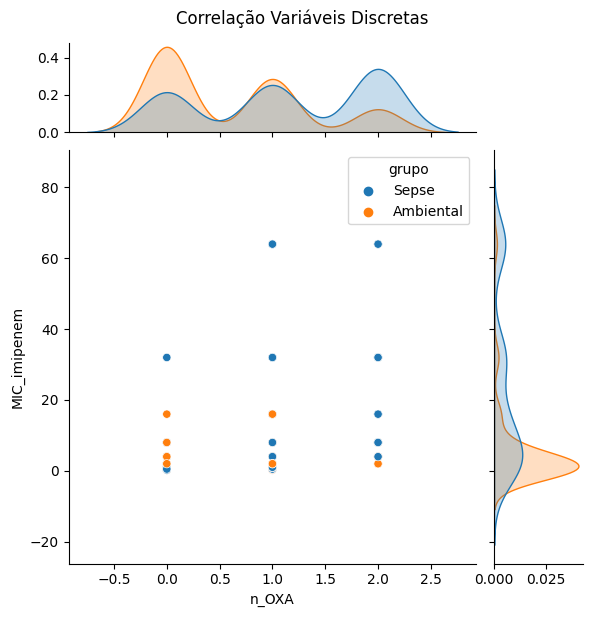

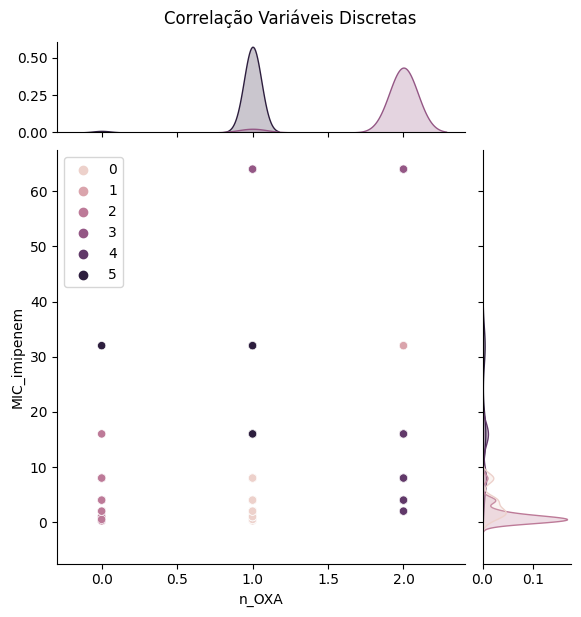

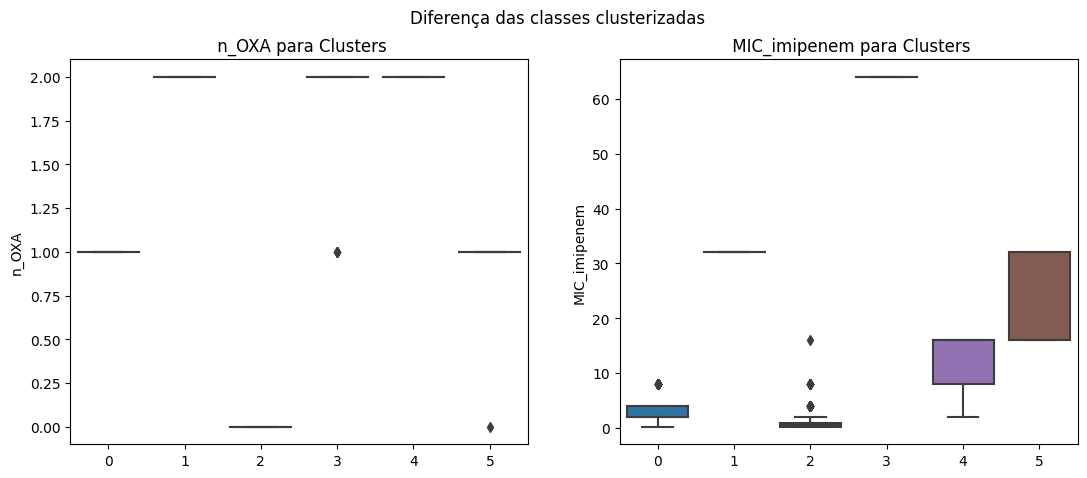

In [ ]:
# Analisando os clusters para variável PPD_log e IFN-γ

i = bivariadas[0][0]
j = bivariadas[0][1]
cluster = Clustering(c1=i, c2=j, df=df_train, modelo=nome_modelo)
cluster.cross_validation()

In [ ]:
# Repetindo as análises de clustering para a combinação de variáveis
# PPD_log e IFN-γ, 100 vezes, para verificar a estabilidade das métricas
# de avaliação de clustering
data = {}
for i in range(100):
    cluster = Clustering(c1="n_tetraciclina", c2="n_polimixinas", df=df_train, modelo=nome_modelo)
    metricas = cluster.cross_validation(print_metricas=False)
    data[i] = metricas

df_metricas_repeti = pd.DataFrame(data).T.rename(
    columns={
        0: "Silhouette",
        1: "Calinski Harabasz",
        2: "Davies Bouldin",
        3: "Adjusted Rand",
        4: "Adjusted Mutual Info",
    }
)
df_metricas_repeti.head()

/home/isabel.ribeiro/.conda/envs/ml_clusterizacao/lib/python3.10/site-packages/sklearn/base.py:1474: ConvergenceWarning: Number of distinct clusters (3) found smaller than n_clusters (4). Possibly due to duplicate points in X.
  return fit_method(estimator, *args, **kwargs)
/home/isabel.ribeiro/.conda/envs/ml_clusterizacao/lib/python3.10/site-packages/sklearn/base.py:1474: ConvergenceWarning: Number of distinct clusters (3) found smaller than n_clusters (4). Possibly due to duplicate points in X.
  return fit_method(estimator, *args, **kwargs)
/home/isabel.ribeiro/.conda/envs/ml_clusterizacao/lib/python3.10/site-packages/sklearn/base.py:1474: ConvergenceWarning: Number of distinct clusters (3) found smaller than n_clusters (4). Possibly due to duplicate points in X.
  return fit_method(estimator, *args, **kwargs)
/home/isabel.ribeiro/.conda/envs/ml_clusterizacao/lib/python3.10/site-packages/sklearn/base.py:1474: ConvergenceWarning: Number of distinct clusters (3) found smaller than n_c

,Silhouette,Calinski Harabasz
0,"[0, 0, 0, 0, 1, 1, 1, 0, 1, 1, 2, 1, 1, 1, 0, ...","(1.0, 1.869472497498417e+31, 0.0, 0.723, 0.597)"
1,"[0, 0, 0, 0, 1, 1, 1, 0, 1, 1, 2, 1, 1, 1, 0, ...","(1.0, 1.869472497498417e+31, 0.0, 0.723, 0.597)"
2,"[0, 0, 0, 0, 1, 1, 1, 0, 1, 1, 2, 1, 1, 1, 0, ...","(1.0, 1.869472497498417e+31, 0.0, 0.723, 0.597)"
3,"[0, 0, 0, 0, 1, 1, 1, 0, 1, 1, 2, 1, 1, 1, 0, ...","(1.0, 1.869472497498417e+31, 0.0, 0.723, 0.597)"
4,"[0, 0, 0, 0, 1, 1, 1, 0, 1, 1, 2, 1, 1, 1, 0, ...","(1.0, 1.869472497498417e+31, 0.0, 0.723, 0.597)"


In [ ]:
df_metricas_repeti.describe()

,Silhouette,Calinski Harabasz
count,100,100
unique,100,1
top,"[0, 0, 0, 0, 1, 1, 1, 0, 1, 1, 2, 1, 1, 1, 0, ...","(1.0, 1.869472497498417e+31, 0.0, 0.723, 0.597)"
freq,1,100


Validação

In [ ]:
#Juntando dados de treino
df_valid = pd.concat([X_valid,y_valid], axis = 1)
df_valid.head()

,n_OXA,n_MBL,n_ISAba1,n_ESBL,n_aminoglicosideos,n_sulfa_trimetoprim,n_quinolonas,n_tetraciclina,n_efluxo_adeS,n_polimixinas,n_virulencia_clinica,n_ilha_AbaR,n_resistencia_metais,n_degradacao_aromaticos,MIC_imipenem,grupo
0,0,0,2,1,2,2,2,1,1,1,2,1,0,0,4.00,Sepse
1,1,0,1,0,3,1,2,1,0,1,0,0,1,1,2.00,Ambiental
2,0,0,0,1,0,1,1,0,0,0,0,0,1,1,0.50,Ambiental
3,1,1,2,0,0,0,0,0,1,0,0,0,2,1,8.00,Ambiental
4,0,0,0,1,0,0,1,0,0,0,0,0,1,1,0.25,Ambiental


In [ ]:
# Repetindo as análises de clustering para a combinação de variáveis
# PPD_log e IFN-γ, 100 vezes, para verificar a estabilidade das métricas
# de avaliação de clustering

data = {}
for i in range(100):
    cluster = Clustering(
        c1=bivariadas[0][0], c2=bivariadas[0][1], df=df_valid, modelo=nome_modelo
    )
    _, metricas = cluster.cross_validation(print_metricas=False)
    data[i] = metricas

df_metricas_repeti_valid_kmeans = pd.DataFrame(data).T.rename(
    columns={
        0: "Silhouette",
        1: "Calinski Harabasz",
        2: "Davies Bouldin",
        3: "Adjusted Rand",
        4: "Adjusted Mutual Info",
    }
)
df_metricas_repeti_valid_kmeans.head()

,Silhouette,Calinski Harabasz,Davies Bouldin,Adjusted Rand,Adjusted Mutual Info
0,0.845,1832.418,0.251,0.045,0.078
1,0.845,1832.418,0.251,0.045,0.078
2,0.845,1832.418,0.251,0.045,0.078
3,0.845,1832.418,0.251,0.045,0.078
4,0.845,1832.418,0.251,0.045,0.078


In [ ]:
# Analisando as métricas de avaliação de clustering para a combinação
# de variáveis PPD_log e IFN-γ, repetidas 100 vezes
df_metricas_repeti_valid_kmeans.describe()

,Silhouette,Calinski Harabasz,Davies Bouldin,Adjusted Rand,Adjusted Mutual Info
count,100.000,1.000000e+02,100.000,1.000000e+02,100.000
mean,0.845,1.832418e+03,0.251,4.500000e-02,0.078
std,0.000,6.855574e-13,0.000,6.973851e-18,0.000
min,0.845,1.832418e+03,0.251,4.500000e-02,0.078
25%,0.845,1.832418e+03,0.251,4.500000e-02,0.078
50%,0.845,1.832418e+03,0.251,4.500000e-02,0.078
75%,0.845,1.832418e+03,0.251,4.500000e-02,0.078
max,0.845,1.832418e+03,0.251,4.500000e-02,0.078


/home/isabel.ribeiro/.conda/envs/ml_clusterizacao/lib/python3.10/site-packages/sklearn/base.py:1474: ConvergenceWarning: Number of distinct clusters (3) found smaller than n_clusters (4). Possibly due to duplicate points in X.
  return fit_method(estimator, *args, **kwargs)
/home/isabel.ribeiro/.conda/envs/ml_clusterizacao/lib/python3.10/site-packages/sklearn/base.py:1474: ConvergenceWarning: Number of distinct clusters (3) found smaller than n_clusters (4). Possibly due to duplicate points in X.
  return fit_method(estimator, *args, **kwargs)
/home/isabel.ribeiro/.conda/envs/ml_clusterizacao/lib/python3.10/site-packages/sklearn/base.py:1474: ConvergenceWarning: Number of distinct clusters (3) found smaller than n_clusters (4). Possibly due to duplicate points in X.
  return fit_method(estimator, *args, **kwargs)
/home/isabel.ribeiro/.conda/envs/ml_clusterizacao/lib/python3.10/site-packages/sklearn/base.py:1474: ConvergenceWarning: Number of distinct clusters (3) found smaller than n_c

=== MELHOR CONFIGURAÇÃO ENCONTRADA VIA cross_val_score ===
Parâmetros: {'n_clusters': 4, 'init': 'k-means++', 'n_init': 'auto'}
Silhouette Score Médio (CV): 1.0000

Silhouette Score -> 1.0
Calinski Harabasz Score -> 6.161187620311881e+31
Davies Bouldin Score -> 0.0
Adjusted Rand Score -> 0.577
Adjusted Mutual Info Score -> 0.451


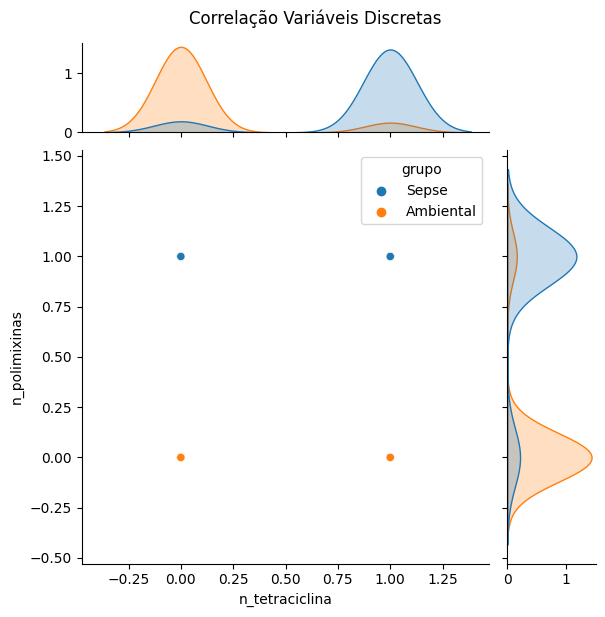

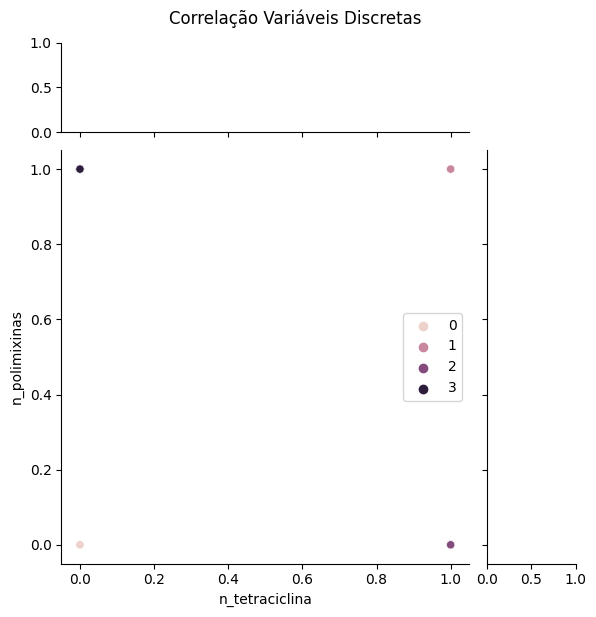

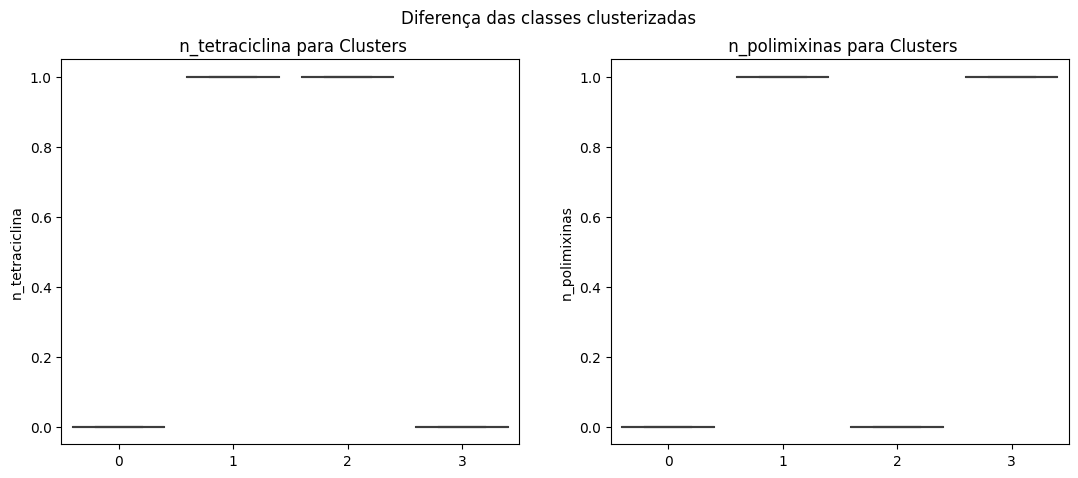

In [ ]:
# Analisando os clusters para variável PPD_log e CD3_2

cluster = Clustering(
    c1=bivariadas[1][0], c2=bivariadas[1][1], df=df_valid, modelo=nome_modelo
)
cluster.cross_validation()

/home/isabel.ribeiro/.conda/envs/ml_clusterizacao/lib/python3.10/site-packages/sklearn/base.py:1474: ConvergenceWarning: Number of distinct clusters (5) found smaller than n_clusters (6). Possibly due to duplicate points in X.
  return fit_method(estimator, *args, **kwargs)
/home/isabel.ribeiro/.conda/envs/ml_clusterizacao/lib/python3.10/site-packages/sklearn/base.py:1474: ConvergenceWarning: Number of distinct clusters (5) found smaller than n_clusters (6). Possibly due to duplicate points in X.
  return fit_method(estimator, *args, **kwargs)
/home/isabel.ribeiro/.conda/envs/ml_clusterizacao/lib/python3.10/site-packages/sklearn/base.py:1474: ConvergenceWarning: Number of distinct clusters (5) found smaller than n_clusters (6). Possibly due to duplicate points in X.
  return fit_method(estimator, *args, **kwargs)
/home/isabel.ribeiro/.conda/envs/ml_clusterizacao/lib/python3.10/site-packages/sklearn/base.py:1474: ConvergenceWarning: Number of distinct clusters (5) found smaller than n_c

=== MELHOR CONFIGURAÇÃO ENCONTRADA VIA cross_val_score ===
Parâmetros: {'n_clusters': 6, 'init': 'k-means++', 'n_init': 'auto'}
Silhouette Score Médio (CV): 0.9700

Silhouette Score -> 1.0
Calinski Harabasz Score -> 1.599913580933539e+33
Davies Bouldin Score -> 0.0
Adjusted Rand Score -> 0.49
Adjusted Mutual Info Score -> 0.479


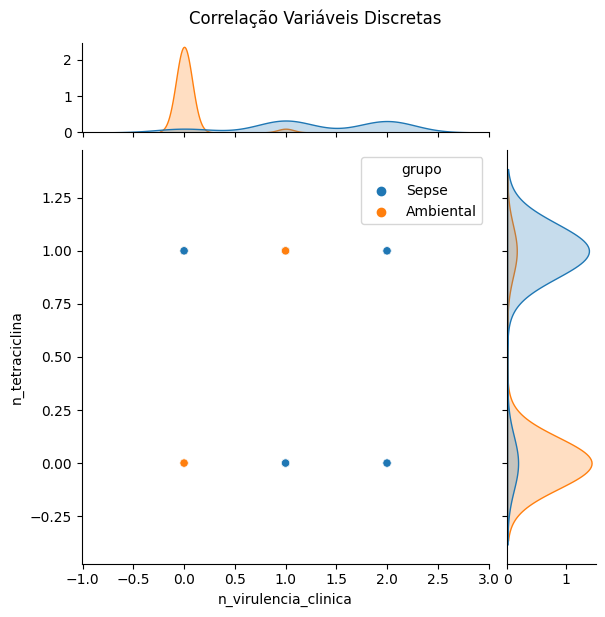

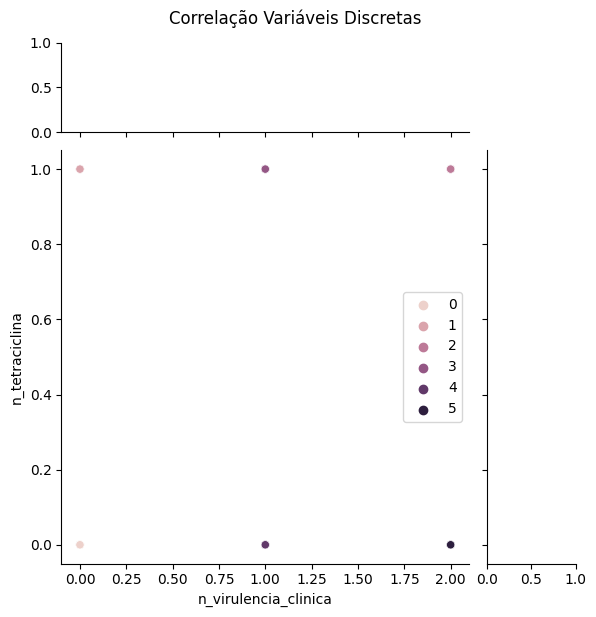

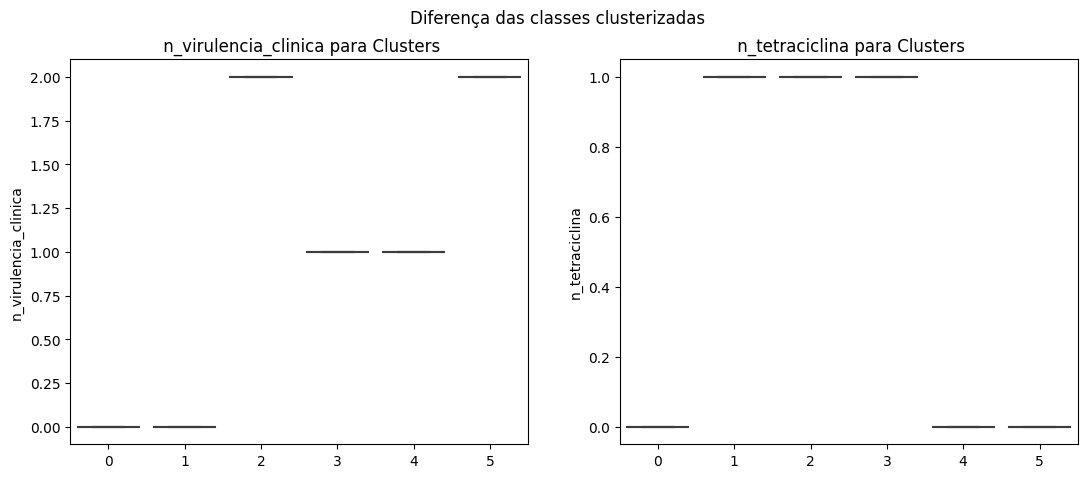

In [ ]:
# Analisando os clusters para variável IFN-γ e CD3_2

cluster = Clustering(
    c1=bivariadas[2][0], c2=bivariadas[2][1], df=df_valid, modelo=nome_modelo
)
cluster.cross_validation()

=== MELHOR CONFIGURAÇÃO ENCONTRADA VIA cross_val_score ===
Parâmetros: {'n_clusters': 6, 'init': 'k-means++', 'n_init': 'auto'}
Silhouette Score Médio (CV): 0.8501

Silhouette Score -> 0.845
Calinski Harabasz Score -> 1832.418
Davies Bouldin Score -> 0.251
Adjusted Rand Score -> 0.045
Adjusted Mutual Info Score -> 0.078


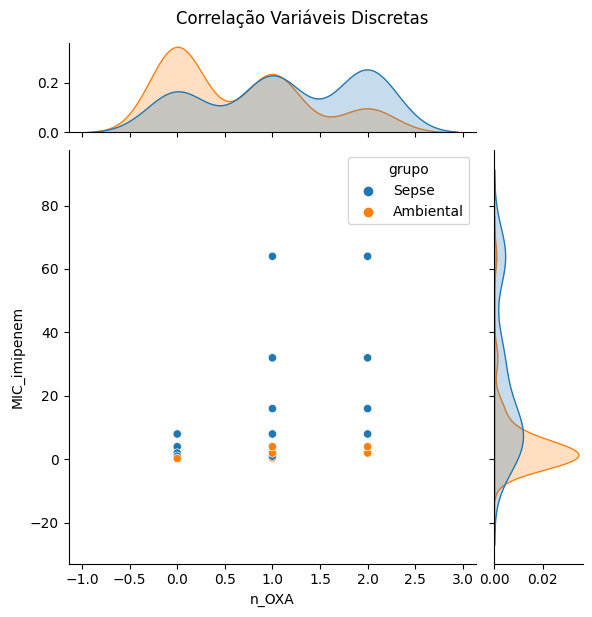

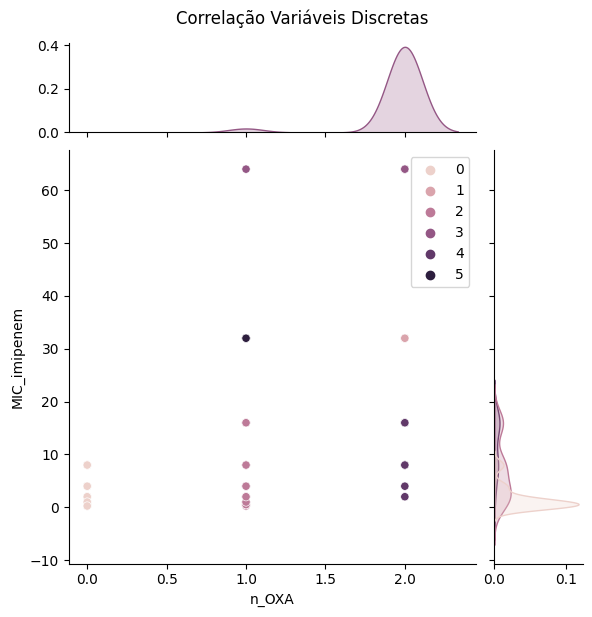

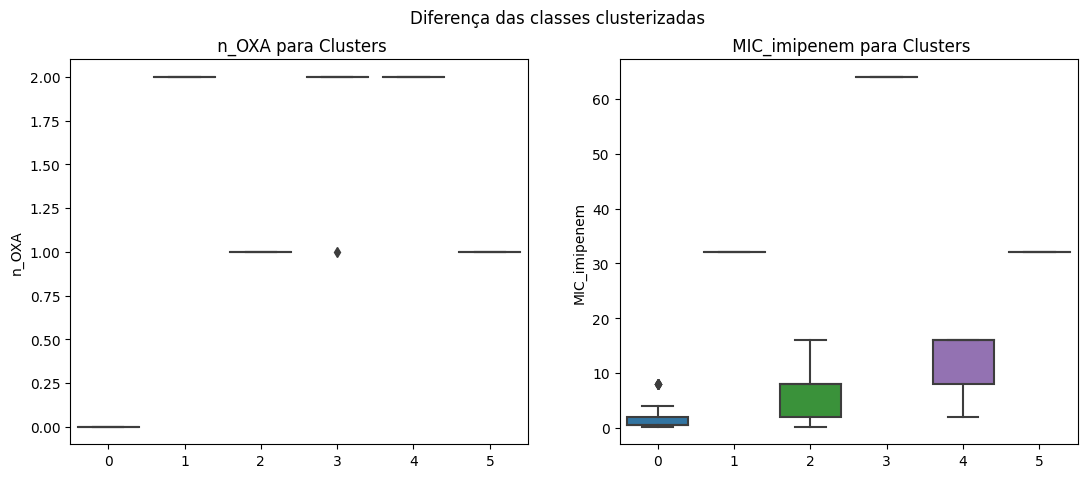

In [ ]:
# Analisando os clusters para variável PPD_log e IFN-γ

cluster = Clustering(
    c1=bivariadas[0][0], c2=bivariadas[0][1], df=df_valid, modelo=nome_modelo
)
cluster.cross_validation()

### DBSCAN

Treino

In [ ]:
# Definindo um objeto de clustering com os dados de treino
nome_modelo = "dbscan"
cluster = Clustering(
    c1=bivariadas[0][0], c2=bivariadas[0][1], df=df_train, modelo=nome_modelo
)
cluster.cross_validation(print_metricas=False)[0][:5]

array([0, 1, 0, 2, 3])

In [ ]:
# Obtendo as métricas de avaliação de clustering para todas as combinações de
# variáveis
data = {}
for i in df_train.columns[:-2]:
    for j in df_train.columns[:-2]:
        if i != j:
            cluster = Clustering(c1=i, c2=j, df=df_train, modelo=nome_modelo)
            _, metricas = cluster.cross_validation(print_metricas=False)
            data[i + "_" + j] = metricas
df_metricas = pd.DataFrame(data).T.rename(
    columns={
        0: "Silhouette",
        1: "Calinski Harabasz",
        2: "Davies Bouldin",
        3: "Adjusted Rand",
        4: "Adjusted Mutual Info",
    }
)
df_metricas.head()

,Silhouette,Calinski Harabasz,Davies Bouldin,Adjusted Rand,Adjusted Mutual Info
n_OXA_n_MBL,1.0,3.594766e+31,0.0,0.113,0.114
n_OXA_n_ISAba1,1.0,1.080668e+32,0.0,0.053,0.070
n_OXA_n_ESBL,1.0,5.067300e+31,0.0,0.136,0.236
n_OXA_n_aminoglicosideos,1.0,9.696349e+31,0.0,0.094,0.202
n_OXA_n_sulfa_trimetoprim,1.0,8.404415e+31,0.0,0.134,0.233


In [ ]:
# Selecionando as melhores combinações de variáveis com base nas métricas de
# avaliação de clustering
display(df_metricas["Silhouette"].nlargest(1))
display(df_metricas["Calinski Harabasz"].nsmallest(1))
display(df_metricas["Davies Bouldin"].nlargest(1))
display(df_metricas["Adjusted Rand"].nlargest(1))
display(df_metricas["Adjusted Mutual Info"].nlargest(1))

n_OXA_n_MBL    1.0
Name: Silhouette, dtype: float64

n_virulencia_clinica_n_degradacao_aromaticos    7.672804e+30
Name: Calinski Harabasz, dtype: float64

n_OXA_n_MBL    0.0
Name: Davies Bouldin, dtype: float64

n_tetraciclina_n_polimixinas    0.723
Name: Adjusted Rand, dtype: float64

n_tetraciclina_n_ilha_AbaR    0.628
Name: Adjusted Mutual Info, dtype: float64

=== MELHOR CONFIGURAÇÃO ENCONTRADA VIA cross_val_score ===
Parâmetros: {'eps': 0.1, 'min_samples': 3, 'metric': 'euclidean'}
Silhouette Score Médio (CV): 1.0000

Silhouette Score -> 1.0
Calinski Harabasz Score -> 1.869472497498417e+31
Davies Bouldin Score -> 0.0
Adjusted Rand Score -> 0.723
Adjusted Mutual Info Score -> 0.597


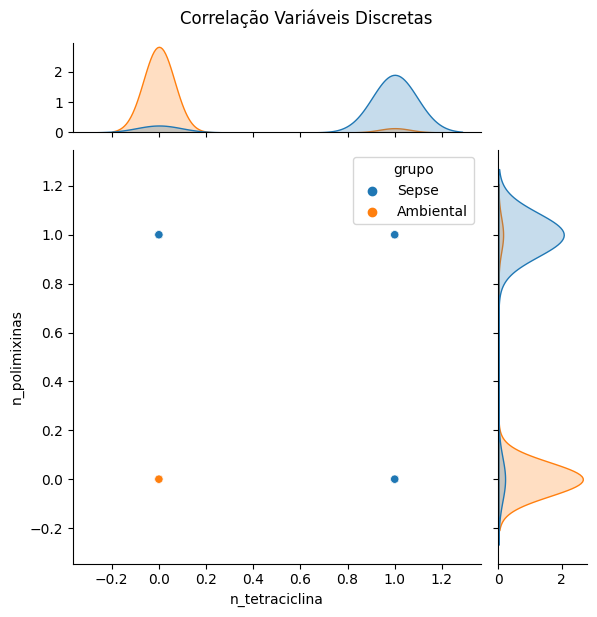

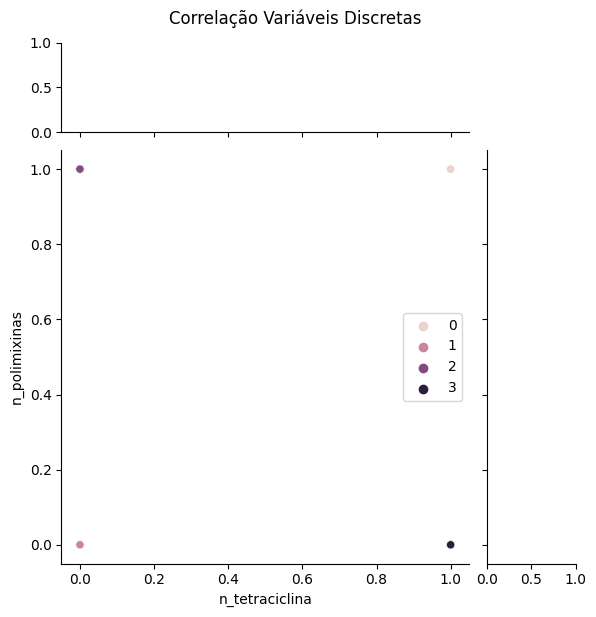

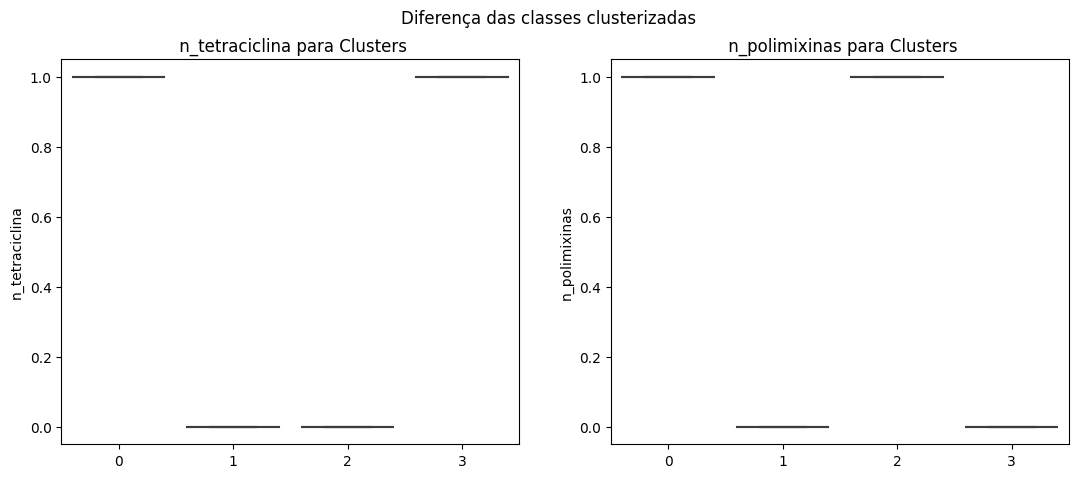

In [ ]:
# Analisando os clusters para variável PPD_log e CD3_2

i = bivariadas[1][0]
j = bivariadas[1][1]
cluster = Clustering(c1=i, c2=j, df=df_train, modelo=nome_modelo)
cluster.cross_validation()

=== MELHOR CONFIGURAÇÃO ENCONTRADA VIA cross_val_score ===
Parâmetros: {'eps': 0.1, 'min_samples': 3, 'metric': 'euclidean'}
Silhouette Score Médio (CV): 0.9969

Silhouette Score -> 1.0
Calinski Harabasz Score -> 9.530664969553124e+30
Davies Bouldin Score -> 0.0
Adjusted Rand Score -> 0.554
Adjusted Mutual Info Score -> 0.542


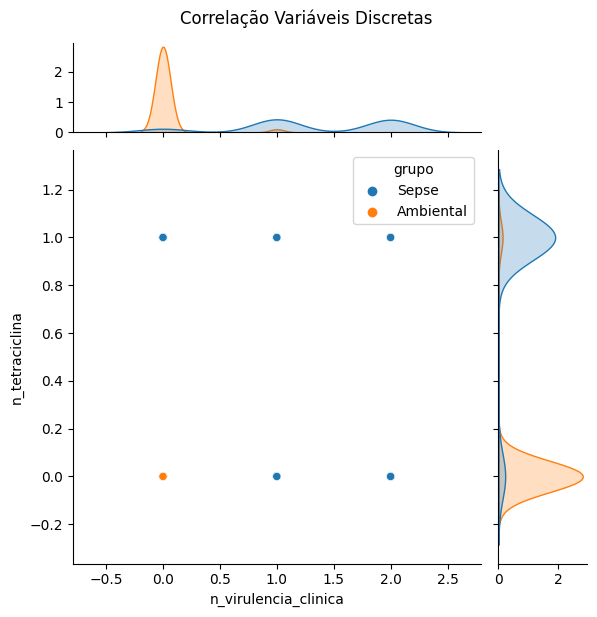

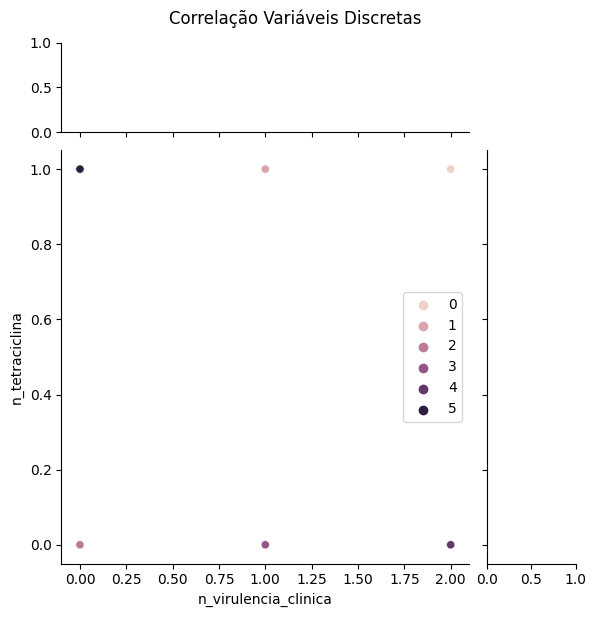

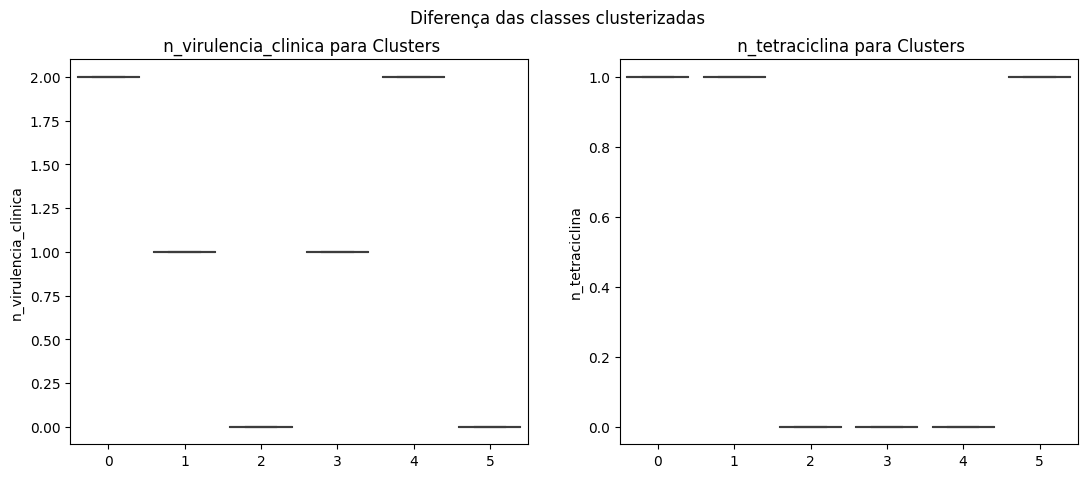

In [ ]:
# Analisando os clusters para variável IFN-γ e CD3_2

i = bivariadas[2][0]
j = bivariadas[2][1]
cluster = Clustering(c1=i, c2=j, df=df_train, modelo=nome_modelo)
cluster.cross_validation()

In [ ]:
df_train.columns

Index(['n_OXA', 'n_MBL', 'n_ISAba1', 'n_ESBL', 'n_aminoglicosideos',
       'n_sulfa_trimetoprim', 'n_quinolonas', 'n_tetraciclina',
       'n_efluxo_adeS', 'n_polimixinas', 'n_virulencia_clinica', 'n_ilha_AbaR',
       'n_resistencia_metais', 'n_degradacao_aromaticos', 'MIC_imipenem',
       'grupo'],
      dtype='object')

=== MELHOR CONFIGURAÇÃO ENCONTRADA VIA cross_val_score ===
Parâmetros: {'eps': 0.2, 'min_samples': 3, 'metric': 'euclidean'}
Silhouette Score Médio (CV): 0.8989

Silhouette Score -> 0.903
Calinski Harabasz Score -> 20080.838
Davies Bouldin Score -> 0.258
Adjusted Rand Score -> 0.057
Adjusted Mutual Info Score -> 0.084


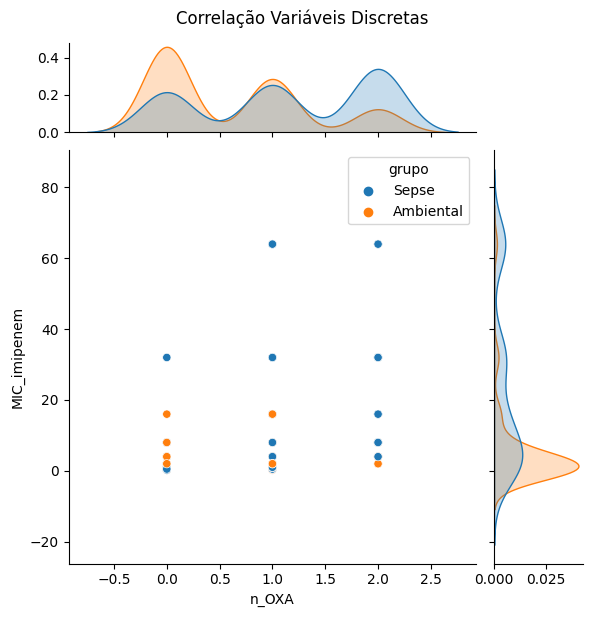

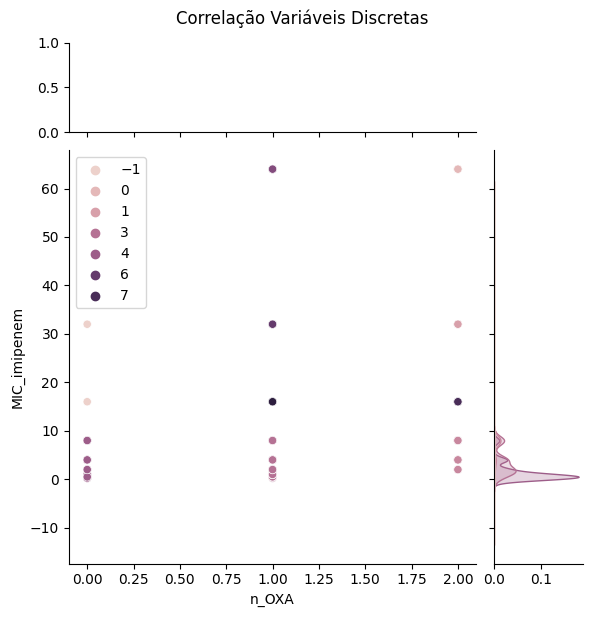

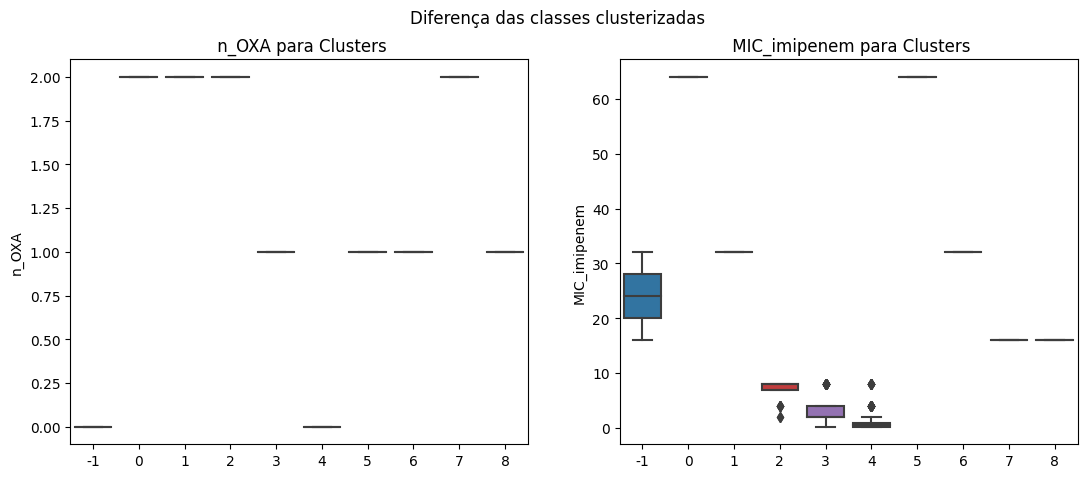

In [ ]:
# Analisando os clusters para variável PPD_log e IFN-γ

i = bivariadas[0][0]
j = bivariadas[0][1]
cluster = Clustering(c1=i, c2=j, df=df_train, modelo=nome_modelo)
cluster.cross_validation()

In [ ]:
df_train.columns

Index(['n_OXA', 'n_MBL', 'n_ISAba1', 'n_ESBL', 'n_aminoglicosideos',
       'n_sulfa_trimetoprim', 'n_quinolonas', 'n_tetraciclina',
       'n_efluxo_adeS', 'n_polimixinas', 'n_virulencia_clinica', 'n_ilha_AbaR',
       'n_resistencia_metais', 'n_degradacao_aromaticos', 'MIC_imipenem',
       'grupo'],
      dtype='object')

In [ ]:
# Repetindo as análises de clustering para a combinação de variáveis
# PPD_log e IFN-γ, 100 vezes, para verificar a estabilidade das métricas
# de avaliação de clustering
data = {}
for i in range(100):
    cluster = Clustering(c1="n_polimixinas", c2="n_tetraciclina", df=df_train, modelo=nome_modelo)
    _, metricas = cluster.cross_validation(print_metricas=False)
    data[i] = metricas

df_metricas_repeti = pd.DataFrame(data).T.rename(
    columns={
        0: "Silhouette",
        1: "Calinski Harabasz",
        2: "Davies Bouldin",
        3: "Adjusted Rand",
        4: "Adjusted Mutual Info",
    }
)
df_metricas_repeti.head()

,Silhouette,Calinski Harabasz,Davies Bouldin,Adjusted Rand,Adjusted Mutual Info
0,1.0,1.869472e+31,0.0,0.723,0.597
1,1.0,1.869472e+31,0.0,0.723,0.597
2,1.0,1.869472e+31,0.0,0.723,0.597
3,1.0,1.869472e+31,0.0,0.723,0.597
4,1.0,1.869472e+31,0.0,0.723,0.597


In [ ]:
# Analisando as métricas de avaliação de clustering para a combinação
# de variáveis PPD_log e IFN-γ, repetidas 100 vezes
df_metricas_repeti.describe()

,Silhouette,Calinski Harabasz,Davies Bouldin,Adjusted Rand,Adjusted Mutual Info
count,100.0,1.000000e+02,100.0,100.000,1.000000e+02
mean,1.0,1.869472e+31,0.0,0.723,5.970000e-01
std,0.0,6.789432e+15,0.0,0.000,1.115816e-16
min,1.0,1.869472e+31,0.0,0.723,5.970000e-01
25%,1.0,1.869472e+31,0.0,0.723,5.970000e-01
50%,1.0,1.869472e+31,0.0,0.723,5.970000e-01
75%,1.0,1.869472e+31,0.0,0.723,5.970000e-01
max,1.0,1.869472e+31,0.0,0.723,5.970000e-01


Validação

In [ ]:
#Juntando dados de treino
df_valid = pd.concat([X_valid,y_valid], axis = 1)
df_valid.head()

,n_OXA,n_MBL,n_ISAba1,n_ESBL,n_aminoglicosideos,n_sulfa_trimetoprim,n_quinolonas,n_tetraciclina,n_efluxo_adeS,n_polimixinas,n_virulencia_clinica,n_ilha_AbaR,n_resistencia_metais,n_degradacao_aromaticos,MIC_imipenem,grupo
0,0,0,2,1,2,2,2,1,1,1,2,1,0,0,4.00,Sepse
1,1,0,1,0,3,1,2,1,0,1,0,0,1,1,2.00,Ambiental
2,0,0,0,1,0,1,1,0,0,0,0,0,1,1,0.50,Ambiental
3,1,1,2,0,0,0,0,0,1,0,0,0,2,1,8.00,Ambiental
4,0,0,0,1,0,0,1,0,0,0,0,0,1,1,0.25,Ambiental


In [ ]:
# Repetindo as análises de clustering para a combinação de variáveis
# PPD_log e IFN-γ, 100 vezes, para verificar a estabilidade das métricas
# de avaliação de clustering
data = {}
for i in range(100):
    cluster = Clustering(
        c1=bivariadas[0][0], c2=bivariadas[0][1], df=df_valid, modelo=nome_modelo
    )
    _, metricas = cluster.cross_validation(print_metricas=False)
    data[i] = metricas

df_metricas_repeti_valid_dbscan = pd.DataFrame(data).T.rename(
    columns={
        0: "Silhouette",
        1: "Calinski Harabasz",
        2: "Davies Bouldin",
        3: "Adjusted Rand",
        4: "Adjusted Mutual Info",
    }
)
df_metricas_repeti_valid_dbscan.head()

,Silhouette,Calinski Harabasz,Davies Bouldin,Adjusted Rand,Adjusted Mutual Info
0,0.848,1861.5,0.221,0.043,0.074
1,0.848,1861.5,0.221,0.043,0.074
2,0.848,1861.5,0.221,0.043,0.074
3,0.848,1861.5,0.221,0.043,0.074
4,0.848,1861.5,0.221,0.043,0.074


In [ ]:
# Analisando as métricas de avaliação de clustering para a combinação
# de variáveis PPD_log e IFN-γ, repetidas 100 vezes
df_metricas_repeti_valid_dbscan.describe()

,Silhouette,Calinski Harabasz,Davies Bouldin,Adjusted Rand,Adjusted Mutual Info
count,1.000000e+02,100.0,1.000000e+02,100.000,1.000000e+02
mean,8.480000e-01,1861.5,2.210000e-01,0.043,7.400000e-02
std,1.115816e-16,0.0,5.579081e-17,0.000,1.394770e-17
min,8.480000e-01,1861.5,2.210000e-01,0.043,7.400000e-02
25%,8.480000e-01,1861.5,2.210000e-01,0.043,7.400000e-02
50%,8.480000e-01,1861.5,2.210000e-01,0.043,7.400000e-02
75%,8.480000e-01,1861.5,2.210000e-01,0.043,7.400000e-02
max,8.480000e-01,1861.5,2.210000e-01,0.043,7.400000e-02


=== MELHOR CONFIGURAÇÃO ENCONTRADA VIA cross_val_score ===
Parâmetros: {'eps': 0.1, 'min_samples': 3, 'metric': 'euclidean'}
Silhouette Score Médio (CV): 0.9811

Silhouette Score -> 1.0
Calinski Harabasz Score -> 6.161187620311881e+31
Davies Bouldin Score -> 0.0
Adjusted Rand Score -> 0.577
Adjusted Mutual Info Score -> 0.451


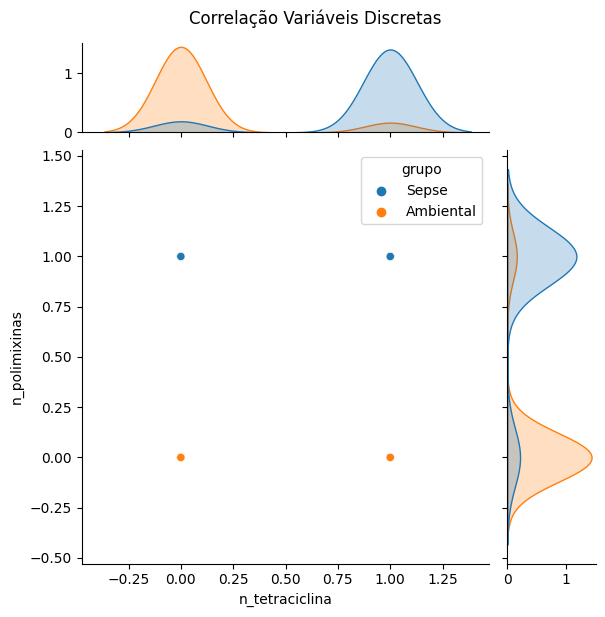

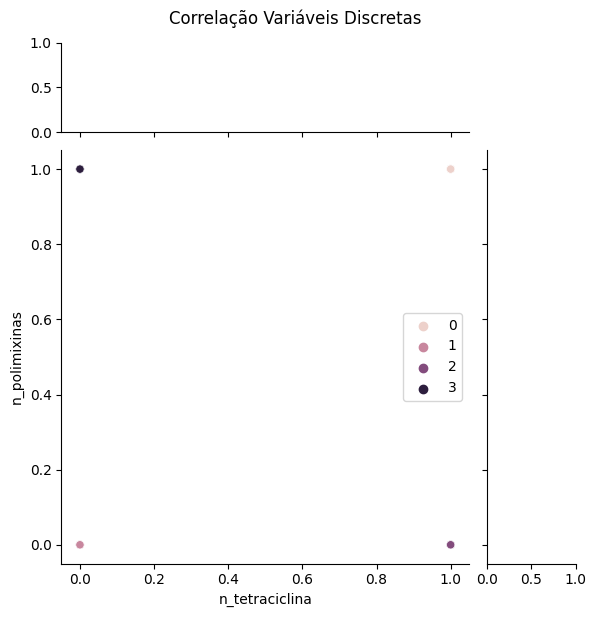

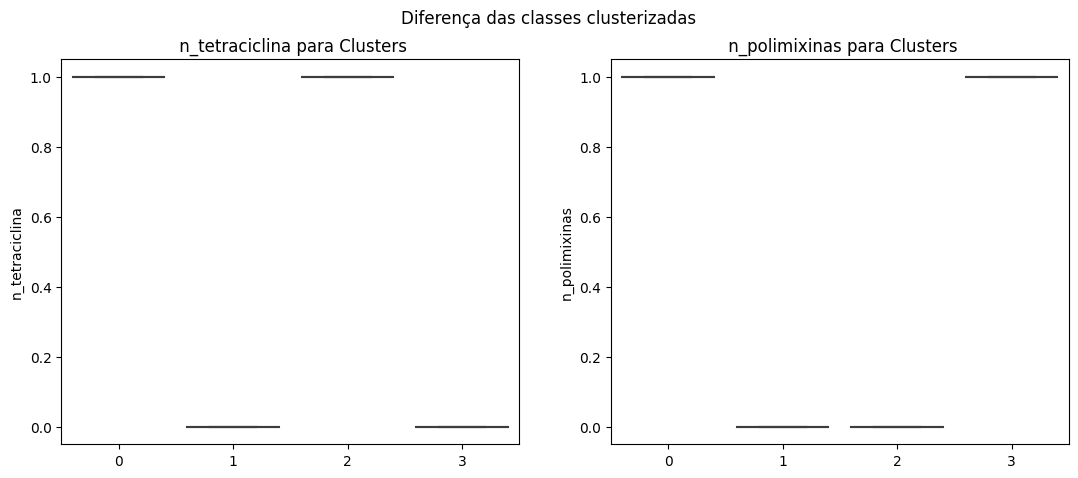

In [ ]:
# Analisando os clusters para variável PPD_log e CD3_2

cluster = Clustering(
    c1=bivariadas[1][0], c2=bivariadas[1][1], df=df_valid, modelo=nome_modelo
)
cluster.cross_validation()

=== MELHOR CONFIGURAÇÃO ENCONTRADA VIA cross_val_score ===
Parâmetros: {'eps': 0.1, 'min_samples': 3, 'metric': 'euclidean'}
Silhouette Score Médio (CV): 0.9202

Silhouette Score -> 1.0
Calinski Harabasz Score -> 1.599913580933539e+33
Davies Bouldin Score -> 0.0
Adjusted Rand Score -> 0.49
Adjusted Mutual Info Score -> 0.479


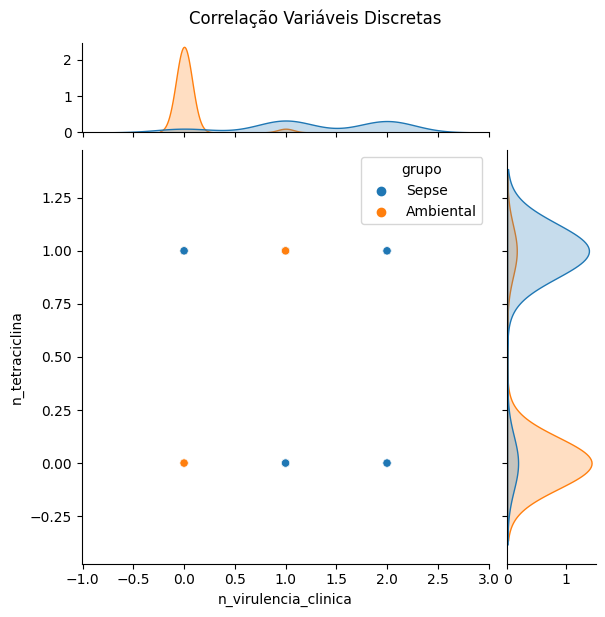

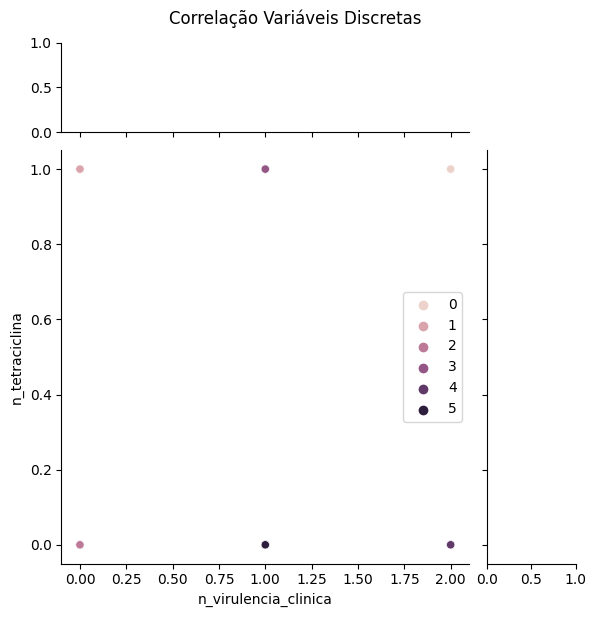

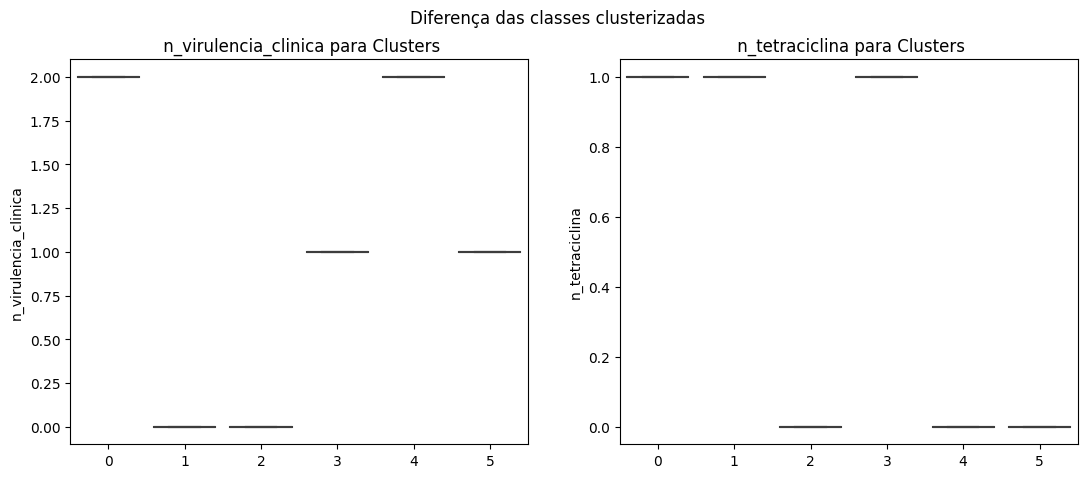

In [ ]:
# Analisando os clusters para variável IFN-γ e CD3_2

cluster = Clustering(
    c1=bivariadas[2][0], c2=bivariadas[2][1], df=df_valid, modelo=nome_modelo
)
cluster.cross_validation()

=== MELHOR CONFIGURAÇÃO ENCONTRADA VIA cross_val_score ===
Parâmetros: {'eps': 0.4, 'min_samples': 3, 'metric': 'euclidean'}
Silhouette Score Médio (CV): 0.8144

Silhouette Score -> 0.848
Calinski Harabasz Score -> 1861.5
Davies Bouldin Score -> 0.221
Adjusted Rand Score -> 0.043
Adjusted Mutual Info Score -> 0.074


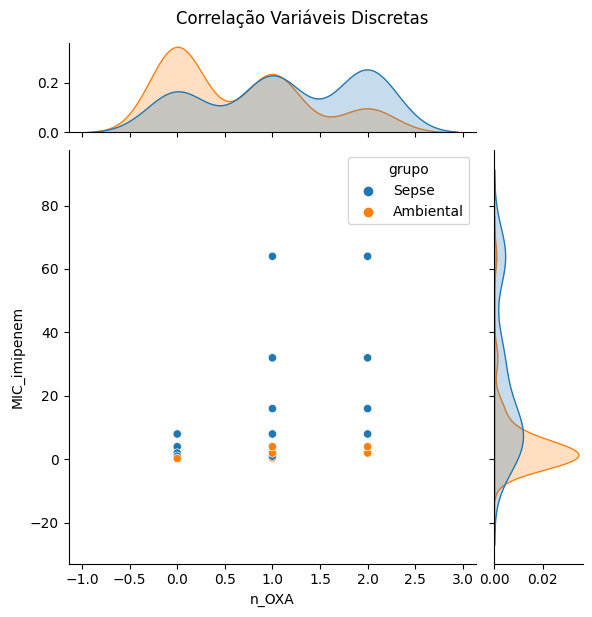

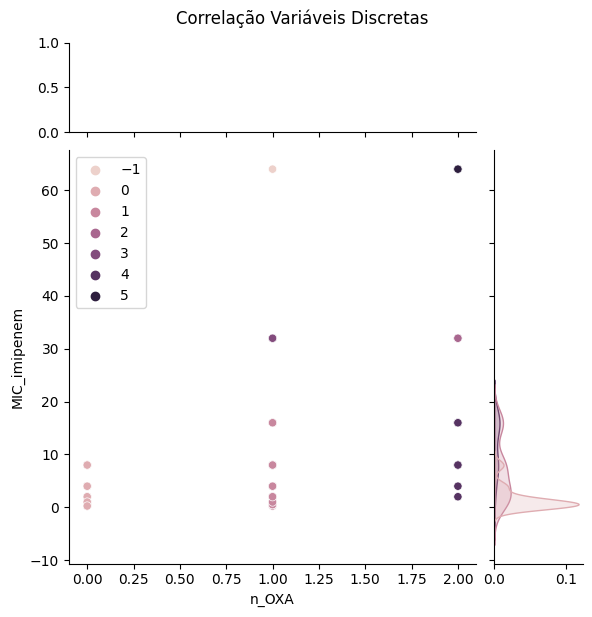

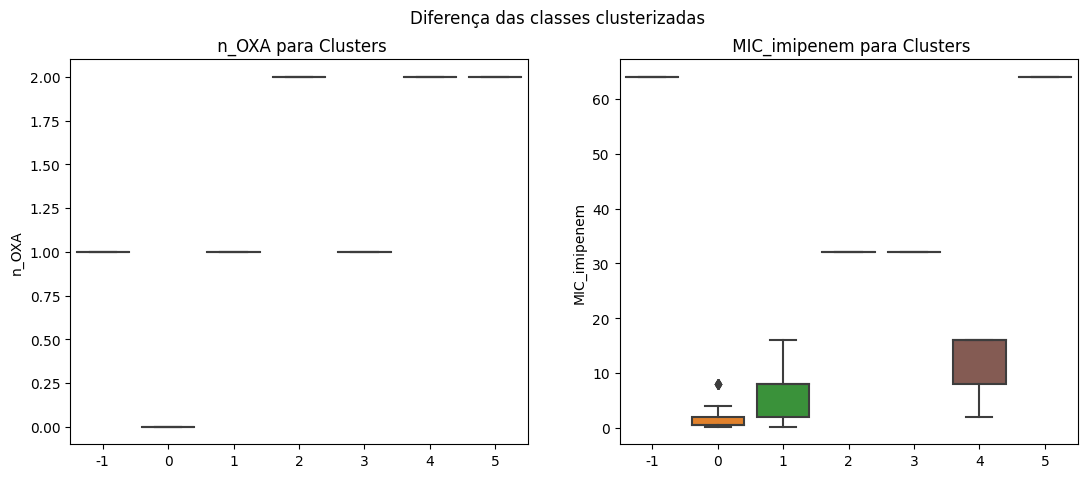

In [ ]:
# Analisando os clusters para variável PPD_log e IFN-γ
cluster = Clustering(
    c1=bivariadas[0][0], c2=bivariadas[0][1], df=df_valid, modelo=nome_modelo
)
cluster.cross_validation()

### Agrupamento Hierarquico

Treino

In [ ]:
param_combinations = [
    {"n_clusters": k, "linkage": "ward", "metric": "euclidean"} for k in [2, 3, 4, 5, 6]
] + [
    {"n_clusters": k, "linkage": linkage, "metric": metric}
    for k in [2, 3, 4, 5, 6]
    for linkage in ["complete", "average", "single"]
    for metric in ["euclidean", "manhattan", "cosine"]
]
param_combinations

[{'n_clusters': 2, 'linkage': 'ward', 'metric': 'euclidean'},
 {'n_clusters': 3, 'linkage': 'ward', 'metric': 'euclidean'},
 {'n_clusters': 4, 'linkage': 'ward', 'metric': 'euclidean'},
 {'n_clusters': 5, 'linkage': 'ward', 'metric': 'euclidean'},
 {'n_clusters': 6, 'linkage': 'ward', 'metric': 'euclidean'},
 {'n_clusters': 2, 'linkage': 'complete', 'metric': 'euclidean'},
 {'n_clusters': 2, 'linkage': 'complete', 'metric': 'manhattan'},
 {'n_clusters': 2, 'linkage': 'complete', 'metric': 'cosine'},
 {'n_clusters': 2, 'linkage': 'average', 'metric': 'euclidean'},
 {'n_clusters': 2, 'linkage': 'average', 'metric': 'manhattan'},
 {'n_clusters': 2, 'linkage': 'average', 'metric': 'cosine'},
 {'n_clusters': 2, 'linkage': 'single', 'metric': 'euclidean'},
 {'n_clusters': 2, 'linkage': 'single', 'metric': 'manhattan'},
 {'n_clusters': 2, 'linkage': 'single', 'metric': 'cosine'},
 {'n_clusters': 3, 'linkage': 'complete', 'metric': 'euclidean'},
 {'n_clusters': 3, 'linkage': 'complete', 'metri

In [ ]:
nome_modelo = "agglomerative"
cluster = Clustering(
    c1=bivariadas[0][0], c2=bivariadas[0][1], df=df_train, modelo=nome_modelo
)
cluster.cross_validation(print_metricas=False)[0][:5]

array([2, 5, 2, 1, 4])

In [ ]:
# Obtendo as métricas de avaliação de clustering para todas as combinações de
# variáveis
data = {}
for i in df_train.columns[:-2]:
    for j in df_train.columns[:-2]:
        if i != j:
            cluster = Clustering(c1=i, c2=j, df=df_train, modelo=nome_modelo)
            _, metricas = cluster.cross_validation(print_metricas=False)
            data[i + "_" + j] = metricas
df_metricas = pd.DataFrame(data).T.rename(
    columns={
        0: "Silhouette",
        1: "Calinski Harabasz",
        2: "Davies Bouldin",
        3: "Adjusted Rand",
        4: "Adjusted Mutual Info",
    }
)
df_metricas.head()

,Silhouette,Calinski Harabasz,Davies Bouldin,Adjusted Rand,Adjusted Mutual Info
n_OXA_n_MBL,1.000,3.594766e+31,0.000,0.113,0.114
n_OXA_n_ISAba1,0.826,1.890637e+03,0.515,0.054,0.070
n_OXA_n_ESBL,0.722,1.193694e+03,0.637,0.121,0.207
n_OXA_n_aminoglicosideos,0.676,1.315513e+03,0.703,0.160,0.206
n_OXA_n_sulfa_trimetoprim,0.737,1.248694e+03,0.645,0.159,0.235


In [ ]:
# Selecionando as melhores combinações de variáveis com base nas métricas de
# avaliação de clustering
display(df_metricas["Silhouette"].nlargest(1))
display(df_metricas["Calinski Harabasz"].nsmallest(1))
display(df_metricas["Davies Bouldin"].nlargest(1))
display(df_metricas["Adjusted Rand"].nlargest(1))
display(df_metricas["Adjusted Mutual Info"].nlargest(1))

n_OXA_n_MBL    1.0
Name: Silhouette, dtype: float64

n_OXA_n_ESBL    1193.694
Name: Calinski Harabasz, dtype: float64

n_ISAba1_n_aminoglicosideos    0.71
Name: Davies Bouldin, dtype: float64

n_tetraciclina_n_polimixinas    0.723
Name: Adjusted Rand, dtype: float64

n_tetraciclina_n_ilha_AbaR    0.628
Name: Adjusted Mutual Info, dtype: float64

=== MELHOR CONFIGURAÇÃO ENCONTRADA VIA cross_val_score ===
Parâmetros: {'n_clusters': 4, 'metric': 'euclidean', 'linkage': 'ward'}
Silhouette Score Médio (CV): 1.0000

Silhouette Score -> 1.0
Calinski Harabasz Score -> 1.869472497498417e+31
Davies Bouldin Score -> 0.0
Adjusted Rand Score -> 0.723
Adjusted Mutual Info Score -> 0.597


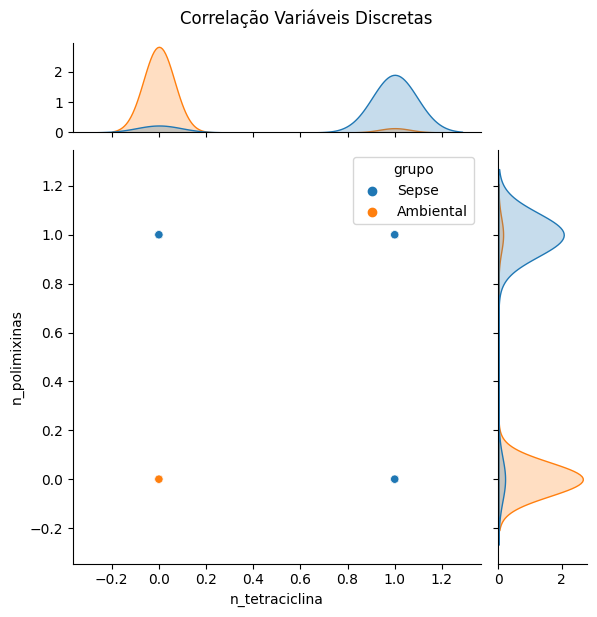

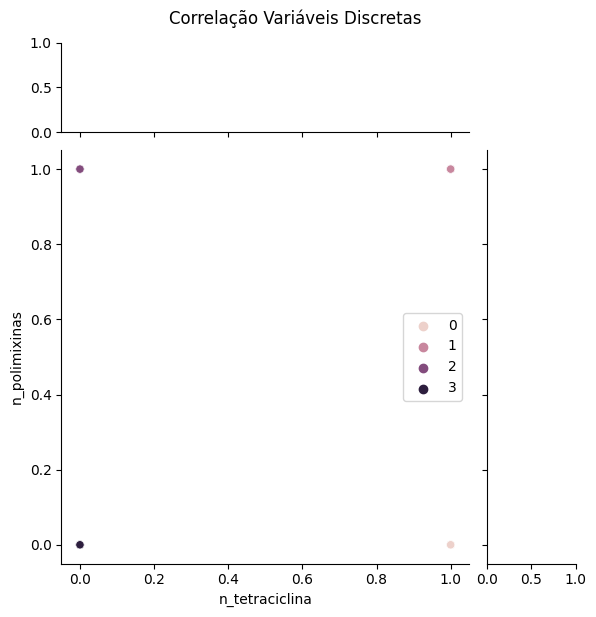

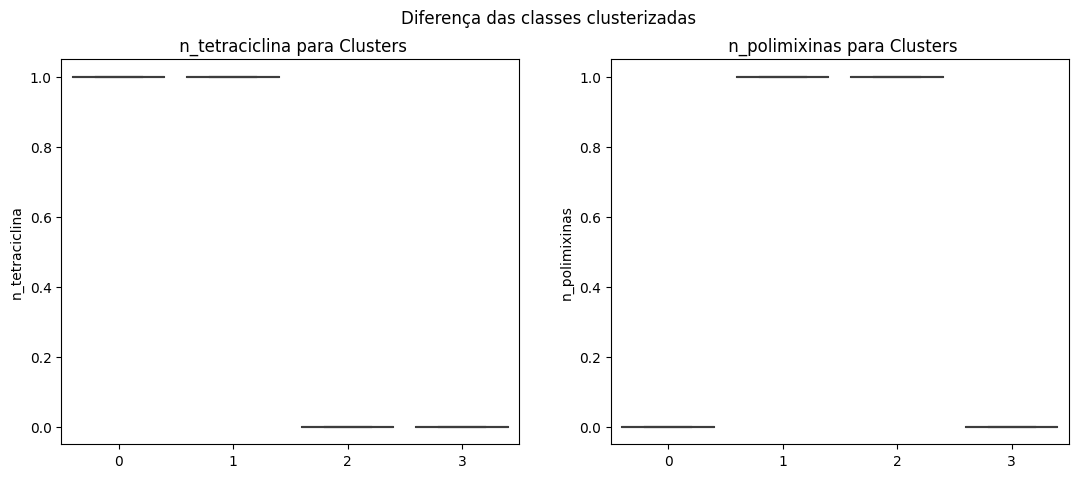

In [ ]:
# Analisando os clusters para variável PPD_log e CD3_2

i = bivariadas[1][0]
j = bivariadas[1][1]
cluster = Clustering(c1=i, c2=j, df=df_train, modelo=nome_modelo)
cluster.cross_validation()

=== MELHOR CONFIGURAÇÃO ENCONTRADA VIA cross_val_score ===
Parâmetros: {'n_clusters': 6, 'metric': 'euclidean', 'linkage': 'ward'}
Silhouette Score Médio (CV): 1.0000

Silhouette Score -> 1.0
Calinski Harabasz Score -> 9.530664969553124e+30
Davies Bouldin Score -> 0.0
Adjusted Rand Score -> 0.554
Adjusted Mutual Info Score -> 0.542


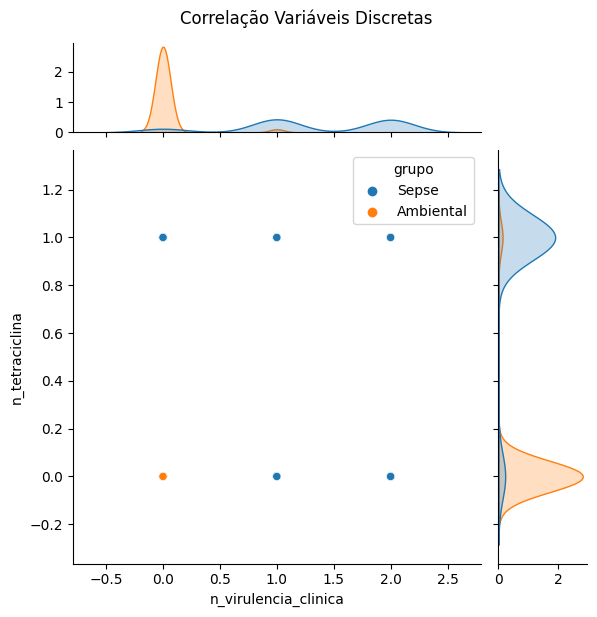

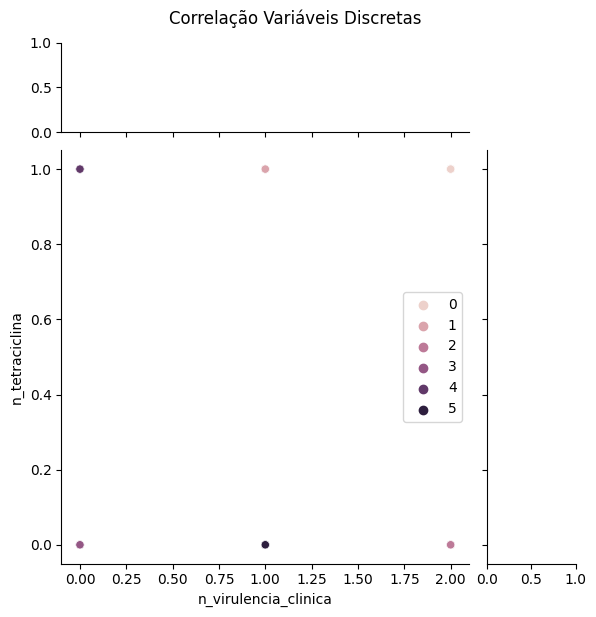

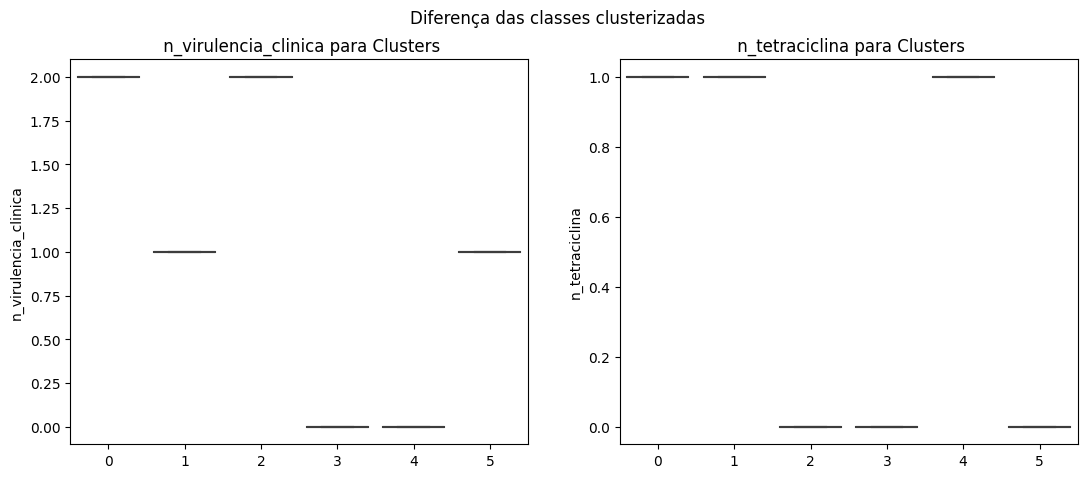

In [ ]:
# Analisando os clusters para variável IFN-γ e CD3_2

i = bivariadas[2][0]
j = bivariadas[2][1]
cluster = Clustering(c1=i, c2=j, df=df_train, modelo=nome_modelo)
cluster.cross_validation()

=== MELHOR CONFIGURAÇÃO ENCONTRADA VIA cross_val_score ===
Parâmetros: {'n_clusters': 6, 'metric': 'euclidean', 'linkage': 'ward'}
Silhouette Score Médio (CV): 0.8674

Silhouette Score -> 0.864
Calinski Harabasz Score -> 7499.785
Davies Bouldin Score -> 0.39
Adjusted Rand Score -> 0.064
Adjusted Mutual Info Score -> 0.09


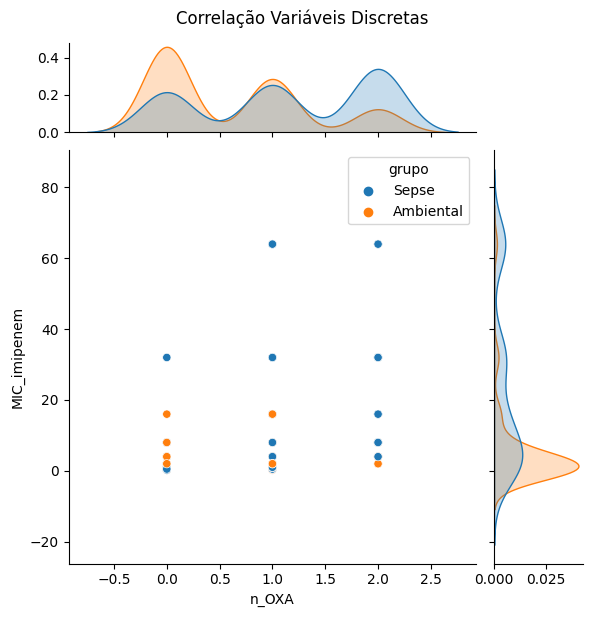

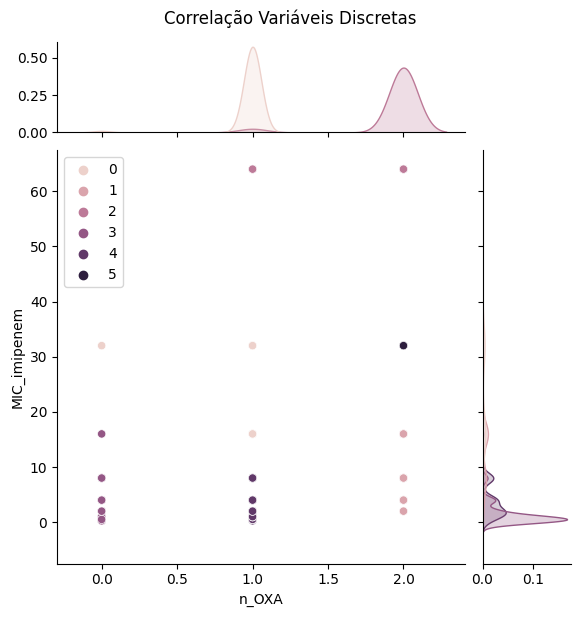

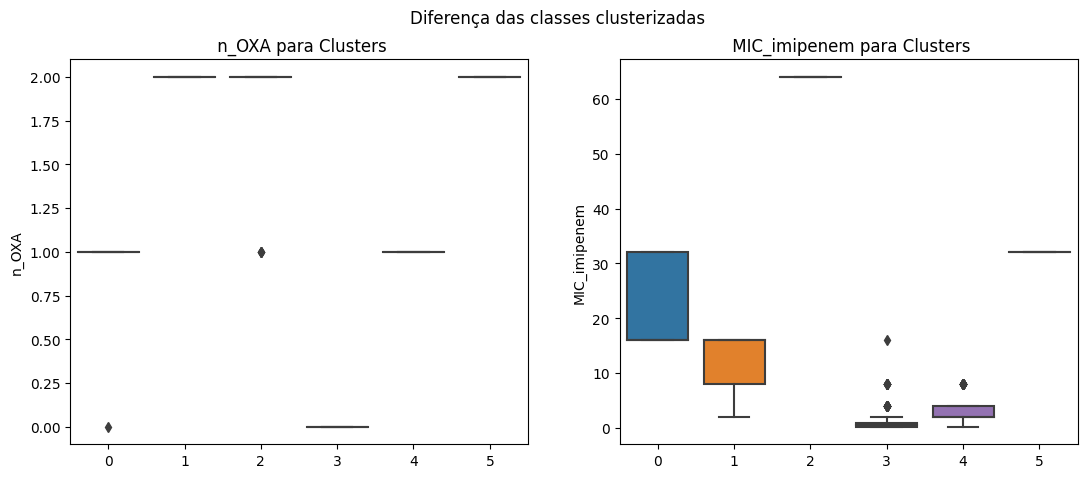

In [ ]:
# Analisando os clusters para variável PPD_log e IFN-γ

i = bivariadas[0][0]
j = bivariadas[0][1]
cluster = Clustering(c1=i, c2=j, df=df_train, modelo=nome_modelo)
cluster.cross_validation()

In [ ]:
# Repetindo as análises de clustering para a combinação de variáveis
# PPD_log e IFN-γ, 100 vezes, para verificar a estabilidade das métricas
# de avaliação de clustering
data = {}
for i in range(100):
    cluster = Clustering(c1="n_polimixinas", c2="n_tetraciclina", df=df_train, modelo=nome_modelo)
    _, metricas = cluster.cross_validation(print_metricas=False)
    data[i] = metricas

df_metricas_repeti = pd.DataFrame(data).T.rename(
    columns={
        0: "Silhouette",
        1: "Calinski Harabasz",
        2: "Davies Bouldin",
        3: "Adjusted Rand",
        4: "Adjusted Mutual Info",
    }
)
df_metricas_repeti.head()

,Silhouette,Calinski Harabasz,Davies Bouldin,Adjusted Rand,Adjusted Mutual Info
0,1.0,1.869472e+31,0.0,0.723,0.597
1,1.0,1.869472e+31,0.0,0.723,0.597
2,1.0,1.869472e+31,0.0,0.723,0.597
3,1.0,1.869472e+31,0.0,0.723,0.597
4,1.0,1.869472e+31,0.0,0.723,0.597


In [ ]:
# Analisando as métricas de avaliação de clustering para a combinação
# de variáveis PPD_log e IFN-γ, repetidas 100 vezes
df_metricas_repeti.describe()

,Silhouette,Calinski Harabasz,Davies Bouldin,Adjusted Rand,Adjusted Mutual Info
count,100.0,1.000000e+02,100.0,100.000,1.000000e+02
mean,1.0,1.869472e+31,0.0,0.723,5.970000e-01
std,0.0,6.789432e+15,0.0,0.000,1.115816e-16
min,1.0,1.869472e+31,0.0,0.723,5.970000e-01
25%,1.0,1.869472e+31,0.0,0.723,5.970000e-01
50%,1.0,1.869472e+31,0.0,0.723,5.970000e-01
75%,1.0,1.869472e+31,0.0,0.723,5.970000e-01
max,1.0,1.869472e+31,0.0,0.723,5.970000e-01


Validação

In [ ]:
#Juntando dados de treino
df_valid = pd.concat([X_valid,y_valid], axis = 1)
df_valid.head()

,n_OXA,n_MBL,n_ISAba1,n_ESBL,n_aminoglicosideos,n_sulfa_trimetoprim,n_quinolonas,n_tetraciclina,n_efluxo_adeS,n_polimixinas,n_virulencia_clinica,n_ilha_AbaR,n_resistencia_metais,n_degradacao_aromaticos,MIC_imipenem,grupo
0,0,0,2,1,2,2,2,1,1,1,2,1,0,0,4.00,Sepse
1,1,0,1,0,3,1,2,1,0,1,0,0,1,1,2.00,Ambiental
2,0,0,0,1,0,1,1,0,0,0,0,0,1,1,0.50,Ambiental
3,1,1,2,0,0,0,0,0,1,0,0,0,2,1,8.00,Ambiental
4,0,0,0,1,0,0,1,0,0,0,0,0,1,1,0.25,Ambiental


In [ ]:
# Repetindo as análises de clustering para a combinação de variáveis
# PPD_log e IFN-γ, 100 vezes, para verificar a estabilidade das métricas
# de avaliação de clustering
data = {}
for i in range(100):
    cluster = Clustering(
        c1=bivariadas[0][0], c2=bivariadas[0][1], df=df_valid, modelo=nome_modelo
    )
    _, metricas = cluster.cross_validation(print_metricas=False)
    data[i] = metricas

df_metricas_repeti_valid_agg = pd.DataFrame(data).T.rename(
    columns={
        0: "Silhouette",
        1: "Calinski Harabasz",
        2: "Davies Bouldin",
        3: "Adjusted Rand",
        4: "Adjusted Mutual Info",
    }
)
df_metricas_repeti_valid_agg.head()

,Silhouette,Calinski Harabasz,Davies Bouldin,Adjusted Rand,Adjusted Mutual Info
0,0.843,2126.8,0.368,0.058,0.081
1,0.843,2126.8,0.368,0.058,0.081
2,0.843,2126.8,0.368,0.058,0.081
3,0.843,2126.8,0.368,0.058,0.081
4,0.843,2126.8,0.368,0.058,0.081


In [ ]:
# Analisando as métricas de avaliação de clustering para a combinação
# de variáveis PPD_log e IFN-γ, repetidas 100 vezes
df_metricas_repeti_valid_agg.describe()

,Silhouette,Calinski Harabasz,Davies Bouldin,Adjusted Rand,Adjusted Mutual Info
count,1.000000e+02,1.000000e+02,1.000000e+02,1.000000e+02,100.000
mean,8.430000e-01,2.126800e+03,3.680000e-01,5.800000e-02,0.081
std,1.115816e-16,9.140766e-13,5.579081e-17,6.973851e-18,0.000
min,8.430000e-01,2.126800e+03,3.680000e-01,5.800000e-02,0.081
25%,8.430000e-01,2.126800e+03,3.680000e-01,5.800000e-02,0.081
50%,8.430000e-01,2.126800e+03,3.680000e-01,5.800000e-02,0.081
75%,8.430000e-01,2.126800e+03,3.680000e-01,5.800000e-02,0.081
max,8.430000e-01,2.126800e+03,3.680000e-01,5.800000e-02,0.081


=== MELHOR CONFIGURAÇÃO ENCONTRADA VIA cross_val_score ===
Parâmetros: {'n_clusters': 3, 'metric': 'euclidean', 'linkage': 'ward'}
Silhouette Score Médio (CV): 0.9543

Silhouette Score -> 0.926
Calinski Harabasz Score -> 1244.682
Davies Bouldin Score -> 0.139
Adjusted Rand Score -> 0.545
Adjusted Mutual Info Score -> 0.42


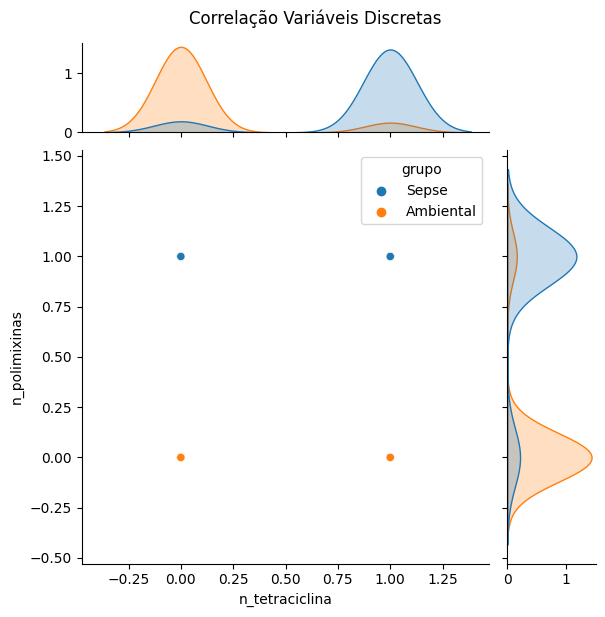

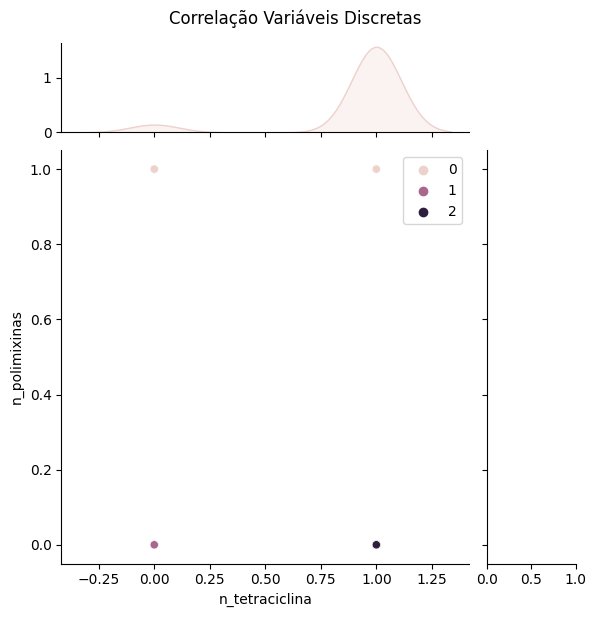

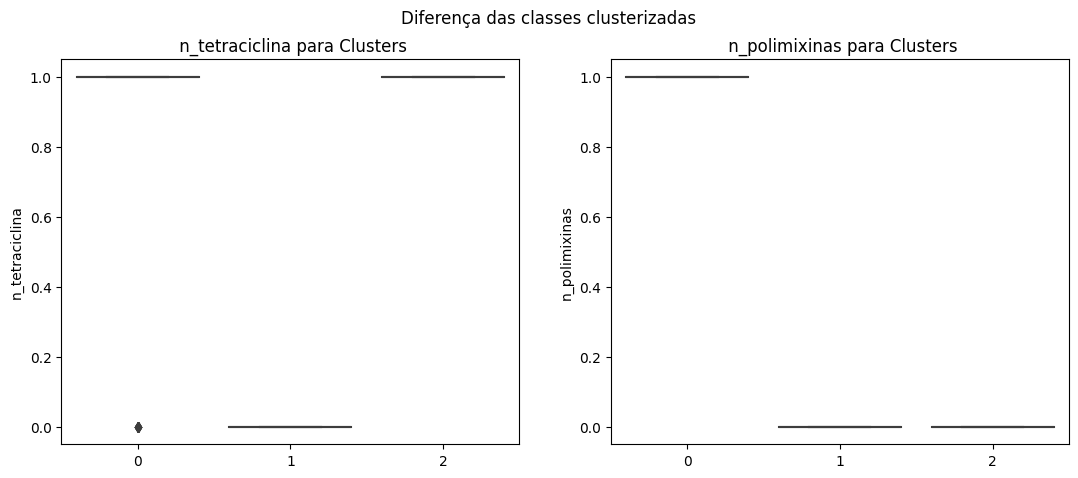

In [ ]:
# Analisando os clusters para variável PPD_log e CD3_2

cluster = Clustering(
    c1=bivariadas[1][0], c2=bivariadas[1][1], df=df_valid, modelo=nome_modelo
)
cluster.cross_validation()

=== MELHOR CONFIGURAÇÃO ENCONTRADA VIA cross_val_score ===
Parâmetros: {'n_clusters': 5, 'metric': 'euclidean', 'linkage': 'ward'}
Silhouette Score Médio (CV): 0.9626

Silhouette Score -> 0.976
Calinski Harabasz Score -> 4523.932
Davies Bouldin Score -> 0.272
Adjusted Rand Score -> 0.492
Adjusted Mutual Info Score -> 0.483


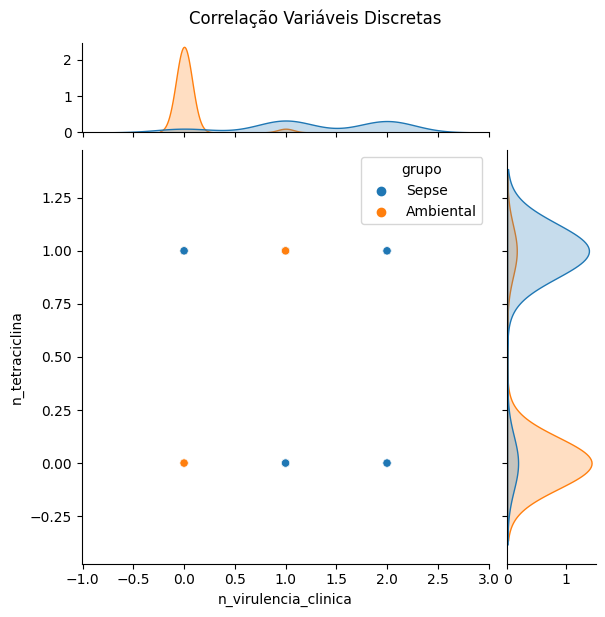

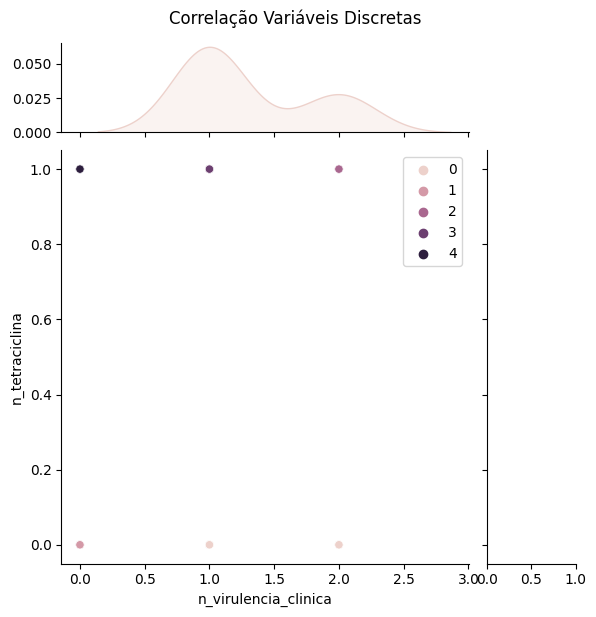

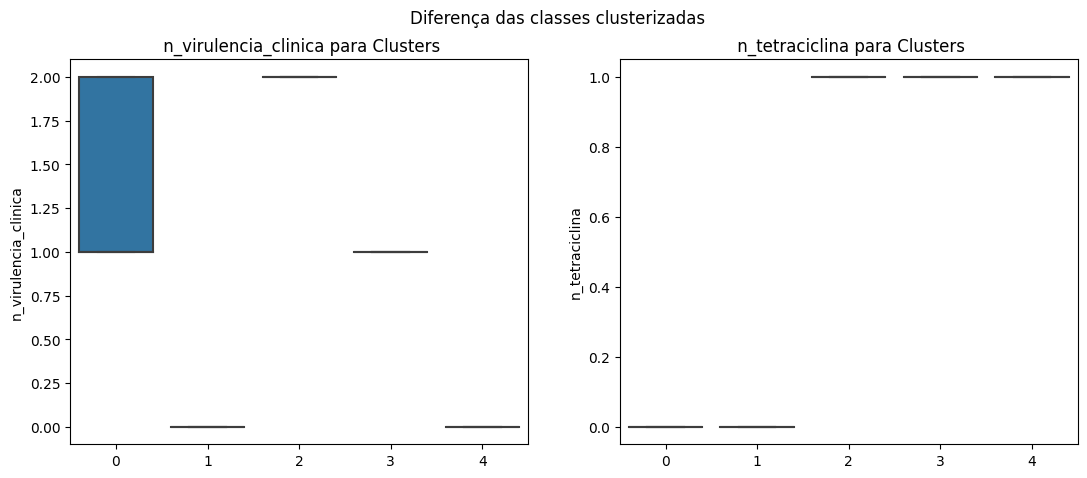

In [ ]:
# Analisando os clusters para variável IFN-γ e CD3_2

cluster = Clustering(
    c1=bivariadas[2][0], c2=bivariadas[2][1], df=df_valid, modelo=nome_modelo
)
cluster.cross_validation()

=== MELHOR CONFIGURAÇÃO ENCONTRADA VIA cross_val_score ===
Parâmetros: {'n_clusters': 6, 'metric': 'euclidean', 'linkage': 'ward'}
Silhouette Score Médio (CV): 0.8480

Silhouette Score -> 0.843
Calinski Harabasz Score -> 2126.8
Davies Bouldin Score -> 0.368
Adjusted Rand Score -> 0.058
Adjusted Mutual Info Score -> 0.081


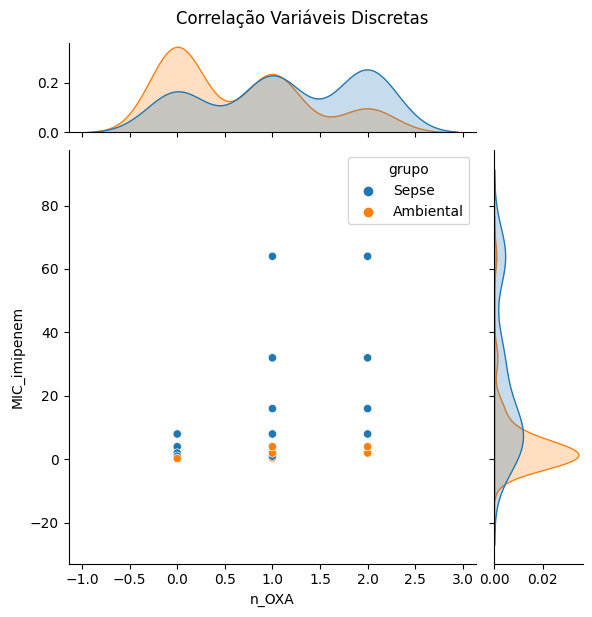

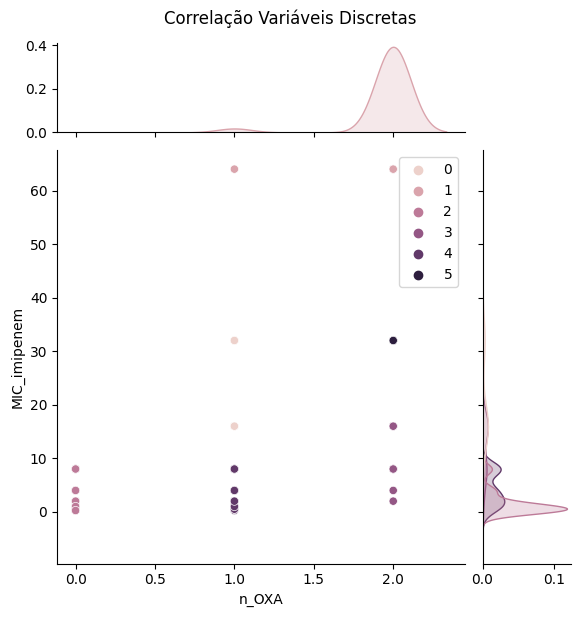

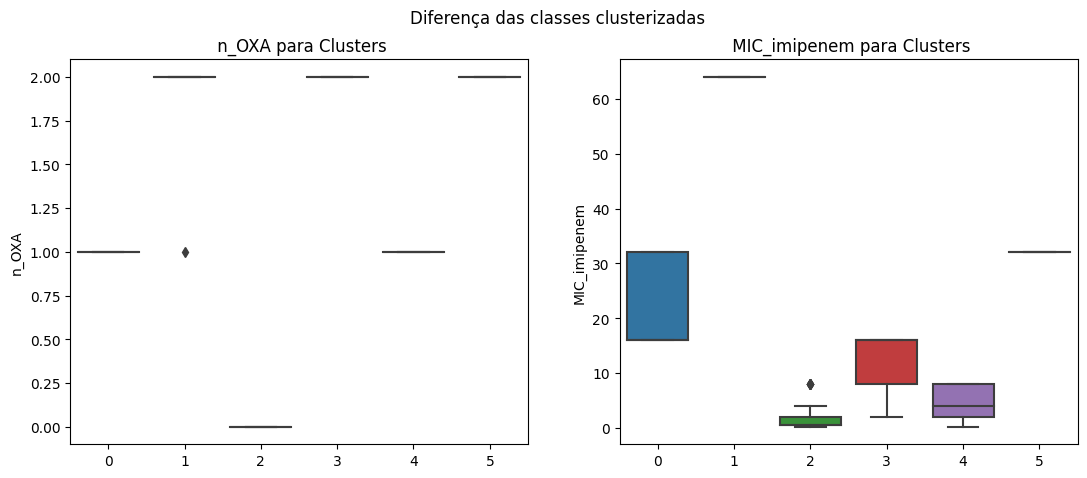

In [ ]:
# Analisando os clusters para variável PPD_log e IFN-γ
cluster = Clustering(
    c1=bivariadas[0][0], c2=bivariadas[0][1], df=df_valid, modelo=nome_modelo
)
cluster.cross_validation()

In [ ]:
import os
from joblib import dump, load

# Criar a pasta data, caso não exista
os.makedirs("./data", exist_ok=True)

# K-means
local = "./data/08_aula_09_df_metricas_repeti_valid_kmeans"

dump(df_metricas_repeti_valid_kmeans, local)

df_metricas_repeti_valid_kmeans = load(local)
df_metricas_repeti_valid_kmeans["algoritmo"] = "kmeans"

In [ ]:
# Agrupando os resultados das métricas de avaliação de clustering para os
# três algoritmos
df_metricas = pd.concat(
    [
        df_metricas_repeti_valid_kmeans,
        df_metricas_repeti_valid_dbscan,
        df_metricas_repeti_valid_agg,
    ],
    axis=0,
)
df_metricas.head()

,Silhouette,Calinski Harabasz,Davies Bouldin,Adjusted Rand,Adjusted Mutual Info,algoritmo
0,0.845,1832.418,0.251,0.045,0.078,kmeans
1,0.845,1832.418,0.251,0.045,0.078,kmeans
2,0.845,1832.418,0.251,0.045,0.078,kmeans
3,0.845,1832.418,0.251,0.045,0.078,kmeans
4,0.845,1832.418,0.251,0.045,0.078,kmeans


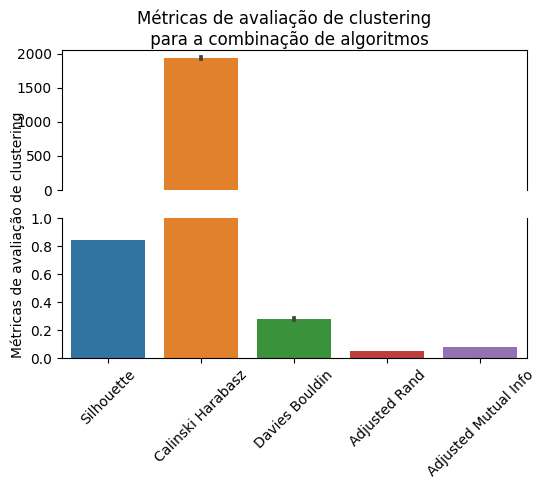

In [ ]:
# Gráfico comparativo das métricas de avaliação de clustering para os três
# algoritmos
fig, ax = plt.subplots(2, 1, figsize=(6, 4))

plt.suptitle("Métricas de avaliação de clustering \n para a combinação de algoritmos")

p = sns.barplot(df_metricas, ax=ax[0])
plt.xticks(rotation=45)
plt.ylim(100, 700)
p.set(xlabel=None)
p.set_xticks([])
p.spines["bottom"].set_visible(False)

q = sns.barplot(df_metricas, ax=ax[1])
plt.xticks(rotation=45)
plt.ylim(0, 1)
q.spines["top"].set_visible(False)

plt.ylabel("Métricas de avaliação de clustering", loc="bottom")

plt.show()

In [ ]:
# Agrupando os resultados das métricas de avaliação de clustering para os três
# algoritmos, com multi-index
df_metricas = pd.concat(
    [
        df_metricas_repeti_valid_kmeans,
        df_metricas_repeti_valid_dbscan,
        df_metricas_repeti_valid_agg,
    ],
    axis=1,
    keys=["kmeans", "dbscan", "agglomerative"],
)
df_metricas.head()

kmeans                                                 \
  Silhouette Calinski Harabasz Davies Bouldin Adjusted Rand   
0      0.845          1832.418          0.251         0.045   
1      0.845          1832.418          0.251         0.045   
2      0.845          1832.418          0.251         0.045   
3      0.845          1832.418          0.251         0.045   
4      0.845          1832.418          0.251         0.045   

                                     dbscan                                   \
  Adjusted Mutual Info algoritmo Silhouette Calinski Harabasz Davies Bouldin   
0                0.078    kmeans      0.848            1861.5          0.221   
1                0.078    kmeans      0.848            1861.5          0.221   
2                0.078    kmeans      0.848            1861.5          0.221   
3                0.078    kmeans      0.848            1861.5          0.221   
4                0.078    kmeans      0.848            1861.5          0.221   

                                     agglomerative                    \
  Adjusted Rand Adjusted Mutual Info    Silhouette Calinski Harabasz   
0         0.043                0.074         0.843            2126.8   
1         0.043                0.074         0.843            2126.8   
2         0.043                0.074         0.843            2126.8   
3         0.043                0.074         0.843            2126.8   
4         0.043                0.074         0.843            2126.8   

                                                     
  Davies Bouldin Adjusted Rand Adjusted Mutual Info  
0          0.368         0.058                0.081  
1          0.368         0.058                0.081  
2          0.368         0.058                0.081  
3          0.368         0.058                0.081  
4          0.368         0.058                0.081

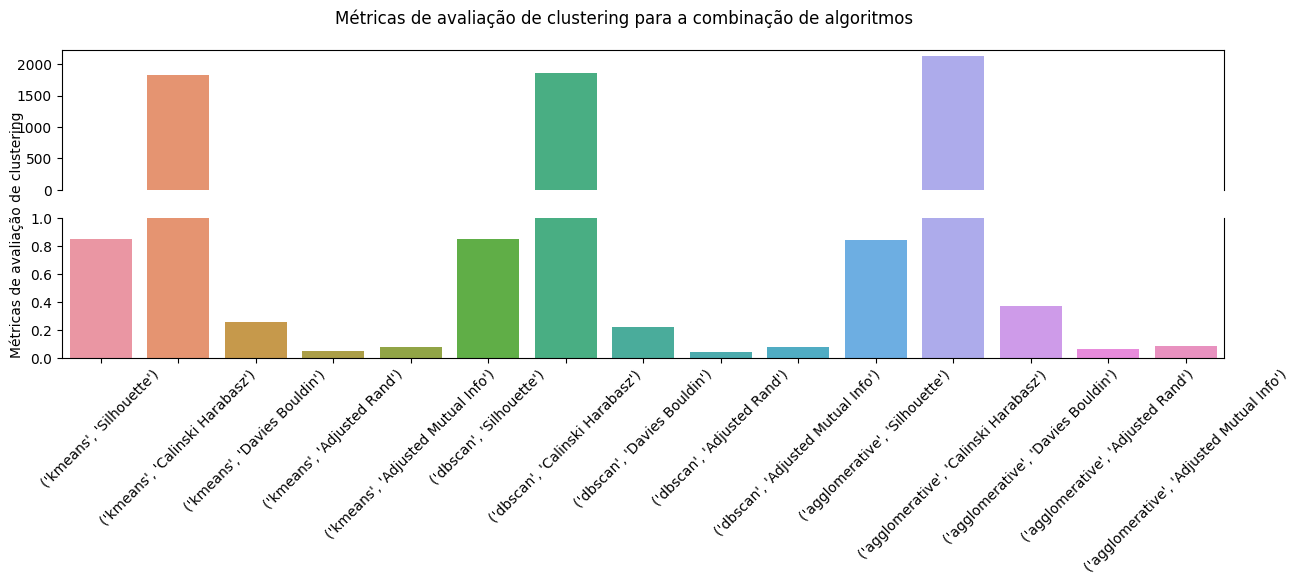

In [ ]:
# Gráfico comparativo das métricas de avaliação de clustering para os três
# algoritmos, com multi-index
fig, ax = plt.subplots(2, 1, figsize=(15, 4))
plt.suptitle("Métricas de avaliação de clustering para a combinação de algoritmos")

p = sns.barplot(df_metricas, ax=ax[0])
plt.xticks(rotation=45)
plt.ylim(100, 700)
p.set(xlabel=None)
p.set_xticks([])
p.spines["bottom"].set_visible(False)

q = sns.barplot(df_metricas, ax=ax[1])
plt.xticks(rotation=45)
plt.ylim(0, 1)
q.spines["top"].set_visible(False)
plt.ylabel("Métricas de avaliação de clustering", loc="bottom")

plt.show()

In [ ]:
def editar_df(df: pd.DataFrame, modelo: str) -> pd.DataFrame:
    """
    Função para editar o dataframe de métricas de avaliação de clustering
    para cada algoritmo, de forma a facilitar a análise comparativa entre
    eles.
        Parametros:
        -----------
            df: pd.DataFrame
                Dataframe de métricas de avaliação de clustering para
                cada algoritmo.
            modelo: str
                Nome do algoritmo de clustering.
        Retorna:
            pd.DataFrame
    """
    colunas = {0: "valores", "index": "metricas"}
    retorno = (
        df.select_dtypes(include="number")
        .median()
        .to_frame()
        .reset_index()
        .rename(columns=colunas)
        .assign(modelo=modelo)
    )
    return retorno

In [ ]:
# Agrupando os resultados das métricas de avaliação de clustering para os três
# algoritmos, com multi-index, e calculando a mediana das métricas

df_metricas = pd.concat(
    (
        editar_df(df=df_metricas_repeti_valid_kmeans, modelo="K-means"),
        editar_df(df=df_metricas_repeti_valid_dbscan, modelo="DBSCAN"),
        editar_df(df=df_metricas_repeti_valid_agg, modelo="Agglomerative"),
    )
)
df_metricas

,metricas,valores,modelo
0,Silhouette,0.845,K-means
1,Calinski Harabasz,1832.418,K-means
2,Davies Bouldin,0.251,K-means
3,Adjusted Rand,0.045,K-means
4,Adjusted Mutual Info,0.078,K-means
0,Silhouette,0.848,DBSCAN
1,Calinski Harabasz,1861.500,DBSCAN
2,Davies Bouldin,0.221,DBSCAN
3,Adjusted Rand,0.043,DBSCAN
4,Adjusted Mutual Info,0.074,DBSCAN


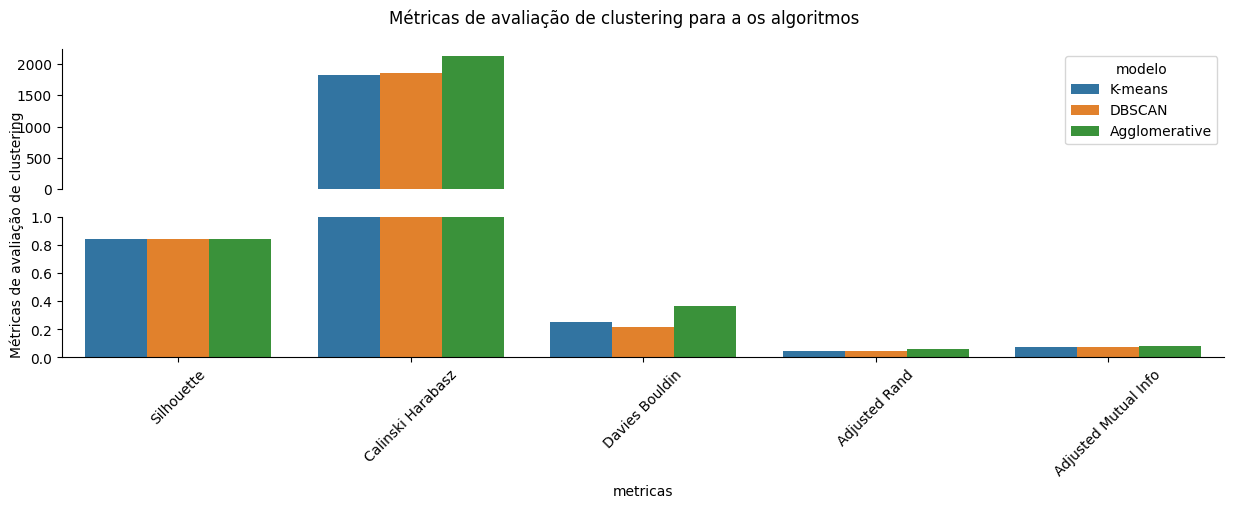

In [ ]:
# Grafico comparativo das métricas de avaliação de clustering para os três
# algoritmos, com multi-index, e calculando a mediana das métricas
fig, ax = plt.subplots(2, 1, figsize=(15, 4))
plt.suptitle("Métricas de avaliação de clustering para a os algoritmos")
p = sns.barplot(x="metricas", y="valores", hue="modelo", data=df_metricas, ax=ax[0])
plt.xticks(rotation=45)
plt.ylim(100, 700)
p.set(xlabel=None, ylabel=None)
p.set_xticks([])
p.spines["bottom"].set_visible(False)
p.spines[["top", "right"]].set_visible(False)

q = sns.barplot(x="metricas", y="valores", hue="modelo", data=df_metricas, ax=ax[1])
plt.xticks(rotation=45)
plt.ylim(0, 1)
q.get_legend().remove()
q.spines[["top", "right"]].set_visible(False)
plt.ylabel("Métricas de avaliação de clustering", loc="bottom")

plt.show()

Testes

In [ ]:
from scipy.stats import chisquare
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.neighbors import KNeighborsClassifier, NearestCentroid
from sklearn.metrics import adjusted_rand_score

In [ ]:
#Juntando dados de treino
df_test = pd.concat([X_test,y_test], axis = 1)
df_test.head()

,n_OXA,n_MBL,n_ISAba1,n_ESBL,n_aminoglicosideos,n_sulfa_trimetoprim,n_quinolonas,n_tetraciclina,n_efluxo_adeS,n_polimixinas,n_virulencia_clinica,n_ilha_AbaR,n_resistencia_metais,n_degradacao_aromaticos,MIC_imipenem,grupo
0,0,0,1,1,0,0,0,0,1,0,0,0,2,1,0.5,Ambiental
1,1,0,0,2,1,1,2,1,1,1,1,1,0,0,4.0,Sepse
2,2,1,2,2,3,2,2,1,1,1,2,1,0,1,32.0,Sepse
3,0,0,1,1,0,0,0,0,0,0,0,0,2,1,2.0,Ambiental
4,1,1,0,1,3,2,2,1,1,1,0,1,0,0,4.0,Sepse


K-means

In [ ]:
bivariadas = [
    ["n_OXA", "MIC_imipenem"],
    ["n_tetraciclina", "n_polimixinas"],
    ["n_virulencia_clinica", "n_tetraciclina"],
    ["n_tetraciclina", "n_ilha_AbaR"],
    ["n_tetraciclina", "n_resistencia_metais"],
    ["n_tetraciclina", "n_degradacao_aromaticos"],
    ["n_efluxo_adeS", "n_virulencia_clinica"],
    ["n_polimixinas", "n_virulencia_clinica"],
    ["n_polimixinas", "n_ilha_AbaR"],
    ["n_polimixinas", "n_resistencia_metais"],
    ["n_polimixinas", "n_degradacao_aromaticos"],
    ["n_polimixinas", "MIC_imipenem"],
    ["n_virulencia_clinica", "n_ilha_AbaR"],
    ["n_virulencia_clinica", "n_resistencia_metais"],
    ["n_virulencia_clinica", "n_degradacao_aromaticos"],
    ["n_virulencia_clinica", "MIC_imipenem"],
    ["n_ilha_AbaR", "n_resistencia_metais"],
    ["n_ilha_AbaR", "n_degradacao_aromaticos"],
    ["n_resistencia_metais", "n_degradacao_aromaticos"],
    ["n_resistencia_metais", "MIC_imipenem"],
    ["n_degradacao_aromaticos", "MIC_imipenem"]
]


In [ ]:
# Testando os modelos de clustering via K-means
resultados = {}
for bivaria in bivariadas:
    i = bivaria[0]
    j = bivaria[1]
    print(i, j, "-" * 100)

    cluster = Clustering(c1=i, c2=j, df=df_train, modelo="kmeans")
    resultados[f"K-means: {i}/{j}"] = cluster.testar_modelo(
        best_param={"n_clusters": 3, "init": "k-means++", "n_init": 10},
        df_test=df_test,
    )

n_OXA MIC_imipenem ----------------------------------------------------------------------------------------------------
 RESULTADOS DA ANÁLISE DE COMPARAÇÃO DE CLUSTERS
Frequências Esperadas na Validação (Treino): 
[22.14285714 10.85714286 67.        ]
Frequências Observadas na Validação:
       [23 12 65]
--------------------------------------------------
Estatística Qui-Quadrado (χ²): 0.2132
p-valor:                        0.8989
--------------------------------------------------
Conclusão: Não rejeitamos H0. A distribuição dos clusters na validação É IGUAL à do treino (p > 0.05).
--------------------------------------------------
Adjusted Rand Index (ARI) entre modelo de Treino e modelo da Validação: 1.0000 (ARI próximo de 1.0 indica que a partição geométrica gerada é virtualmente idêntica)
n_tetraciclina n_polimixinas ----------------------------------------------------------------------------------------------------
 RESULTADOS DA ANÁLISE DE COMPARAÇÃO DE CLUSTERS
Frequências Espe

DBSCAN

In [ ]:
# Testando os modelos de clustering via DBSCAN
for bivaria in bivariadas:
    i = bivaria[0]
    j = bivaria[1]
    print(i, j, "-" * 100)

    cluster = Clustering(c1=i, c2=j, df=df_train, modelo="dbscan")
    resultados[f"DBSCAN: {i}/{j}"] = cluster.testar_modelo(
        best_param={"eps": 0.5, "min_samples": 10, "metric": "euclidean"},
        df_test=df_test,
    )

n_OXA MIC_imipenem ----------------------------------------------------------------------------------------------------
 RESULTADOS DA COMPARAÇÃO DE CLUSTERS (DBSCAN)
Clusters identificados no Treino:       
[-1  0  1  2  3  4  5  6  7  8  9 10 11 12 13]
Frequências Esperadas na Validação:     
[ 2.   10.29  8.14  7.57  4.    6.29 29.57  3.43  4.86  3.43  4.    1.57
  4.57  5.43  4.86]
Frequências Observadas na Validação:    
[ 2 12  9  4  6  7 26  1  7  5  4  0  4  5  8]
-------------------------------------------------------
Estatística Qui-Quadrado (χ²): 10.6692
p-valor:                        0.7118
-------------------------------------------------------
Conclusão: Não rejeitamos H0. A distribuição dos clusters
na validação É IGUAL à do treino (p > 0.05).
-------------------------------------------------------
Adjusted Rand Index (ARI) entre predição e DBSCAN direto na Validação: 0.2555
n_tetraciclina n_polimixinas -------------------------------------------------------------------

Agrupamento Hierarquico

In [ ]:
# Testando os modelos de clustering via Agrupamento Hierarquico
for bivaria in bivariadas:
    i = bivaria[0]
    j = bivaria[1]
    print(i, j, "-" * 100)

    cluster = Clustering(c1=i, c2=j, df=df_train, modelo="agglomerative")
    resultados[f"Agg: {i}/{j}"] = cluster.testar_modelo(
        best_param={"n_clusters": 2, "metric": "euclidean", "linkage": "average"},
        df_test=df_test,
    )

n_OXA MIC_imipenem ----------------------------------------------------------------------------------------------------
 RESULTADOS DA COMPARAÇÃO (AGGLOMERATIVE CLUSTERING)
Clusters no Treino:                  
[0 1]
Frequências Esperadas na Validação:  
[89.14 10.86]
Frequências Observadas na Validação:  
[88 12]
------------------------------------------------------------
Estatística Qui-Quadrado (χ²): 0.1350
p-valor:                        0.7134
------------------------------------------------------------
Conclusão: Não rejeitamos H0. A distribuição dos clusters na validação É IGUAL à do treino (p > 0.05).
------------------------------------------------------------
Adjusted Rand Index (ARI) entre projeção e agrupamento direto: 1.0000
n_tetraciclina n_polimixinas ----------------------------------------------------------------------------------------------------
 RESULTADOS DA COMPARAÇÃO (AGGLOMERATIVE CLUSTERING)
Clusters no Treino:                  
[0 1]
Frequências Esperadas na

In [ ]:
resultados

{'K-means: n_OXA/MIC_imipenem': True,
 'K-means: n_tetraciclina/n_polimixinas': True,
 'K-means: n_virulencia_clinica/n_tetraciclina': True,
 'K-means: n_tetraciclina/n_ilha_AbaR': True,
 'K-means: n_tetraciclina/n_resistencia_metais': True,
 'K-means: n_tetraciclina/n_degradacao_aromaticos': True,
 'K-means: n_efluxo_adeS/n_virulencia_clinica': True,
 'K-means: n_polimixinas/n_virulencia_clinica': True,
 'K-means: n_polimixinas/n_ilha_AbaR': False,
 'K-means: n_polimixinas/n_resistencia_metais': True,
 'K-means: n_polimixinas/n_degradacao_aromaticos': True,
 'K-means: n_polimixinas/MIC_imipenem': True,
 'K-means: n_virulencia_clinica/n_ilha_AbaR': True,
 'K-means: n_virulencia_clinica/n_resistencia_metais': True,
 'K-means: n_virulencia_clinica/n_degradacao_aromaticos': True,
 'K-means: n_virulencia_clinica/MIC_imipenem': True,
 'K-means: n_ilha_AbaR/n_resistencia_metais': True,
 'K-means: n_ilha_AbaR/n_degradacao_aromaticos': False,
 'K-means: n_resistencia_metais/n_degradacao_aromat